In [39]:
#creating folder and structure
import os

root = "/content/drive/MyDrive/Week5_DataScience_SwiftLog_SharinMideva"
folders = [
    "Data/Original_Datasets",
    "Data/Cleaned_Datasets",
    "Notebook",
    "Reports",
    "Visualizations/Charts",
    "Visualizations/Dashboards",
    "Presentation",
]
for f in folders:
    os.makedirs(os.path.join(root, f), exist_ok=True)

In [40]:
#checking for the file
import os
print(sorted(os.listdir(root + "/Data/Original_Datasets/")))

['SwiftLog_Customers.csv', 'SwiftLog_Data_Dictionary.csv', 'SwiftLog_Delivery_Performance.csv', 'SwiftLog_Employees.csv', 'SwiftLog_Inventory.csv', 'SwiftLog_Order_Items.csv', 'SwiftLog_Orders.csv', 'SwiftLog_Products.csv', 'SwiftLog_Returns.csv', 'SwiftLog_Shipments.csv', 'SwiftLog_Suppliers.csv', 'SwiftLog_Warehouses.csv']


In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

RAW    = root + "/Data/Original_Datasets/"
CLEAN  = root + "/Data/Cleaned_Datasets/"
CHARTS = root + "/Visualizations/Charts/"

In [42]:
#loading the files
dfs = {}
for f in sorted(glob.glob(RAW + "*.csv")):
    name = os.path.basename(f).replace("SwiftLog_", "").replace(".csv", "").lower()
    dfs[name] = pd.read_csv(f)

print(len(dfs), "datasets loaded:")
print(list(dfs.keys()))

12 datasets loaded:
['customers', 'data_dictionary', 'delivery_performance', 'employees', 'inventory', 'order_items', 'orders', 'products', 'returns', 'shipments', 'suppliers', 'warehouses']


In [43]:
data_dict = dfs.pop("data_dictionary")
print(len(dfs), "data tables:", list(dfs.keys()))
data_dict

11 data tables: ['customers', 'delivery_performance', 'employees', 'inventory', 'order_items', 'orders', 'products', 'returns', 'shipments', 'suppliers', 'warehouses']


,File,Description
0,SwiftLog_Inventory.csv,Dataset
1,SwiftLog_Products.csv,Dataset
2,SwiftLog_Order_Items.csv,Dataset
3,SwiftLog_Warehouses.csv,Dataset
4,SwiftLog_Orders.csv,Dataset
5,SwiftLog_Customers.csv,Dataset
6,SwiftLog_Delivery_Performance.csv,Dataset
7,SwiftLog_Employees.csv,Dataset
8,SwiftLog_Shipments.csv,Dataset
9,SwiftLog_Suppliers.csv,Dataset


In [44]:
overview = pd.DataFrame({
    name: {"rows": df.shape[0], "cols": df.shape[1],
           "nulls": df.isna().sum().sum(), "duplicates": df.duplicated().sum()}
    for name, df in dfs.items()
}).T
display(overview)

for name, df in dfs.items():
    print(f"\n=== {name.upper()} {df.shape} ===")
    print(df.dtypes.to_string())

,rows,cols,nulls,duplicates
customers,1000,3,0,0
delivery_performance,5000,3,0,0
employees,200,2,0,0
inventory,4000,3,0,3
order_items,15000,4,0,0
orders,5000,4,0,0
products,250,3,0,0
returns,500,3,0,0
shipments,5000,4,0,0
suppliers,150,2,0,0



=== CUSTOMERS (1000, 3) ===
CustomerID      object
CustomerName    object
City            object

=== DELIVERY_PERFORMANCE (5000, 3) ===
ShipmentID    object
Status        object
DelayDays      int64

=== EMPLOYEES (200, 2) ===
EmployeeID     object
WarehouseID    object

=== INVENTORY (4000, 3) ===
WarehouseID    object
ProductID      object
Stock           int64

=== ORDER_ITEMS (15000, 4) ===
OrderItemID    object
OrderID        object
ProductID      object
Quantity        int64

=== ORDERS (5000, 4) ===
OrderID       object
CustomerID    object
OrderDate     object
Status        object

=== PRODUCTS (250, 3) ===
ProductID     object
Category      object
UnitPrice    float64

=== RETURNS (500, 3) ===
ReturnID    object
OrderID     object
Reason      object

=== SHIPMENTS (5000, 4) ===
ShipmentID     object
OrderID        object
WarehouseID    object
DelayDays       int64

=== SUPPLIERS (150, 2) ===
SupplierID      object
SupplierName    object

=== WAREHOUSES (15, 2) ===
WarehouseI

**Starter assumptions list**

Suppliers has no key linking it to other tables, so it is analysed as a standalone.

Warehouse utilisation is a proxy, because capacity wasn’t provided.

Repeated Warehouse-Product inventory rows are treated as stock movements and summed.

Revenue is calculated as Quantity × UnitPrice, since there is no amount column.

“Delayed” is defined as DelayDays > 0 (pending what the data shows).

Delivery duration isn’t available, so DelayDays is the delivery-time measure.

In [45]:
# 1. Primary keys (inventory excluded, since repeats are stock movements)
primary_keys = {
    "customers": ["CustomerID"],
    "orders": ["OrderID"],
    "order_items": ["OrderItemID"],
    "products": ["ProductID"],
    "suppliers": ["SupplierID"],
    "warehouses": ["WarehouseID"],
    "shipments": ["ShipmentID"],
    "delivery_performance": ["ShipmentID"],
    "employees": ["EmployeeID"],
    "returns": ["ReturnID"],
}

for table_name, key_columns in primary_keys.items():
    table = dfs[table_name]
    n_duplicate_keys = table.duplicated(subset=key_columns).sum()
    n_null_keys = table[key_columns].isna().sum().sum()
    print(f"{table_name:22} duplicate keys: {n_duplicate_keys:<4} null keys: {n_null_keys}")

# 2. Foreign keys:
foreign_keys = [
    # (child table, FK column, parent table, parent key column)
    ("orders", "CustomerID", "customers", "CustomerID"),
    ("order_items", "OrderID", "orders", "OrderID"),
    ("order_items", "ProductID", "products", "ProductID"),
    ("shipments", "OrderID", "orders", "OrderID"),
    ("shipments", "WarehouseID", "warehouses", "WarehouseID"),
    ("delivery_performance", "ShipmentID", "shipments", "ShipmentID"),
    ("returns", "OrderID", "orders", "OrderID"),
    ("employees", "WarehouseID", "warehouses", "WarehouseID"),
    ("inventory", "WarehouseID", "warehouses", "WarehouseID"),
    ("inventory", "ProductID", "products", "ProductID"),
]

results = []
for child_table, child_column, parent_table, parent_column in foreign_keys:
    child_values = dfs[child_table][child_column]
    parent_values = dfs[parent_table][parent_column]
    n_orphans = (~child_values.isin(parent_values)).sum()
    results.append((child_table, child_column, parent_table, parent_column, n_orphans))

display(pd.DataFrame(results, columns=["child_table", "fk_column", "parent_table", "parent_key", "orphans"]))

# 3. Inventory: aggregate stock movements per Warehouse-Product
inv_agg = dfs["inventory"].groupby(["WarehouseID","ProductID"], as_index=False)["Stock"].sum()
print("inventory rows:", len(dfs["inventory"]), "->", len(inv_agg), "after aggregation")

# 4. Do the two DelayDays columns agree?
chk = dfs["shipments"].merge(dfs["delivery_performance"], on="ShipmentID", suffixes=("_ship","_dp"))
print("rows matched:", len(chk), "| mismatched DelayDays:", (chk["DelayDays_ship"] != chk["DelayDays_dp"]).sum())

# 5. What does Status mean? Compare it with DelayDays
print(dfs["delivery_performance"].groupby("Status")["DelayDays"].describe())

# 6. Category consistency
for table, column in [("customers","City"),("products","Category"),("orders","Status"),
             ("delivery_performance","Status"),("returns","Reason"),("warehouses","Location")]:
    print(f"\n{table}.{column}"); print(dfs[table][column].value_counts(dropna=False))

# 7. Numeric sanity
for table, column in [("shipments","DelayDays"),("delivery_performance","DelayDays"),
             ("inventory","Stock"),("order_items","Quantity"),("products","UnitPrice")]:
    print(f"\n{table}.{column}"); print(dfs[table][column].describe())

# 8. Date range
dates = pd.to_datetime(dfs["orders"]["OrderDate"], errors="coerce")
print("\nOrderDate unparseable:", dates.isna().sum(), "| range:", dates.min(), "to", dates.max())

customers              duplicate keys: 0    null keys: 0
orders                 duplicate keys: 0    null keys: 0
order_items            duplicate keys: 0    null keys: 0
products               duplicate keys: 0    null keys: 0
suppliers              duplicate keys: 0    null keys: 0
warehouses             duplicate keys: 0    null keys: 0
shipments              duplicate keys: 0    null keys: 0
delivery_performance   duplicate keys: 0    null keys: 0
employees              duplicate keys: 0    null keys: 0
returns                duplicate keys: 0    null keys: 0


,child_table,fk_column,parent_table,parent_key,orphans
0,orders,CustomerID,customers,CustomerID,0
1,order_items,OrderID,orders,OrderID,0
2,order_items,ProductID,products,ProductID,0
3,shipments,OrderID,orders,OrderID,0
4,shipments,WarehouseID,warehouses,WarehouseID,0
5,delivery_performance,ShipmentID,shipments,ShipmentID,0
6,returns,OrderID,orders,OrderID,0
7,employees,WarehouseID,warehouses,WarehouseID,0
8,inventory,WarehouseID,warehouses,WarehouseID,0
9,inventory,ProductID,products,ProductID,0


inventory rows: 4000 -> 2455 after aggregation
rows matched: 5000 | mismatched DelayDays: 0
          count      mean       std  min  25%  50%  75%  max
Status                                                      
Delayed  3186.0  5.032643  1.398430  3.0  4.0  5.0  6.0  7.0
On Time  1814.0  1.000000  0.820988  0.0  0.0  1.0  2.0  2.0

customers.City
City
Ibadan    262
Kano      253
Lagos     246
Abuja     239
Name: count, dtype: int64

products.Category
Category
Fashion        95
Electronics    78
Food           77
Name: count, dtype: int64

orders.Status
Status
Pending      1716
Delivered    1658
Cancelled    1626
Name: count, dtype: int64

delivery_performance.Status
Status
Delayed    3186
On Time    1814
Name: count, dtype: int64

returns.Reason
Reason
Late Delivery    185
Wrong Item       163
Damaged          152
Name: count, dtype: int64

warehouses.Location
Location
Lagos    8
Abuja    4
Kano     3
Name: count, dtype: int64

shipments.DelayDays
count    5000.00000
mean        3.5

**Key validation findings:**

All 10 primary keys are unique and non-null. All 10 foreign key relationships have zero orphan records, so referential integrity holds. `inventory` has a composite key (WarehouseID + ProductID), but repeated combinations are stock movements, aggregated by summing Stock (4,000 rows to 2,455). `suppliers` has no link to any other table and is analysed standalone.

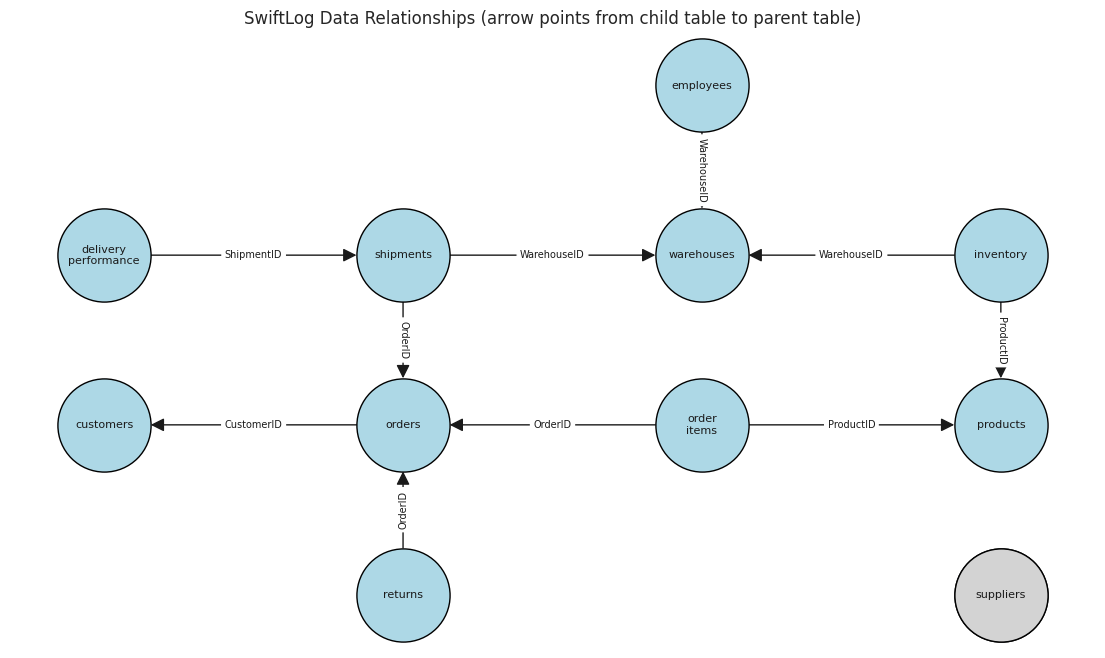

In [46]:
import networkx as nx

# Relationship diagram
relationships = [
    ("orders", "customers", "CustomerID"),
    ("order_items", "orders", "OrderID"),
    ("order_items", "products", "ProductID"),
    ("shipments", "orders", "OrderID"),
    ("shipments", "warehouses", "WarehouseID"),
    ("delivery_performance", "shipments", "ShipmentID"),
    ("returns", "orders", "OrderID"),
    ("employees", "warehouses", "WarehouseID"),
    ("inventory", "warehouses", "WarehouseID"),
    ("inventory", "products", "ProductID"),
]

graph = nx.DiGraph()
graph.add_nodes_from(dfs.keys())
for child, parent, link_column in relationships:
    graph.add_edge(child, parent, label=link_column)

positions = {
    "customers": (0, 2), "orders": (3, 2), "order_items": (6, 2), "products": (9, 2),
    "returns": (3, 0), "shipments": (3, 4), "delivery_performance": (0, 4),
    "warehouses": (6, 4), "employees": (6, 6), "inventory": (9, 4),
    "suppliers": (9, 0),
}
labels = {name: name.replace("_", "\n") for name in graph.nodes}

plt.figure(figsize=(14, 8))
nx.draw_networkx_nodes(graph, positions, node_size=4500, node_color="lightblue", edgecolors="black")
nx.draw_networkx_nodes(graph, positions, nodelist=["suppliers"], node_size=4500,
                       node_color="lightgrey", edgecolors="black")
nx.draw_networkx_labels(graph, positions, labels=labels, font_size=8)
nx.draw_networkx_edges(graph, positions, arrows=True, arrowsize=20, node_size=4500)
nx.draw_networkx_edge_labels(graph, positions, edge_labels=nx.get_edge_attributes(graph, "label"), font_size=7)
plt.title("SwiftLog Data Relationships (arrow points from child table to parent table)")
plt.axis("off")
plt.savefig(CHARTS + "00_data_relationship_diagram.png", dpi=150, bbox_inches="tight")
plt.show()

In [47]:
# 2. Three more checks
orders = dfs["orders"]
shipments = dfs["shipments"]
delivery = dfs["delivery_performance"]
returns = dfs["returns"]

print("\n===== CHECK A: shipments per order =====")
print("each order has at most one shipment:", shipments["OrderID"].is_unique)
print("share of orders with a shipment:", round(orders["OrderID"].isin(shipments["OrderID"]).mean(), 3))

print("\n===== CHECK B: order status vs delivery status =====")
order_delivery = (orders.merge(shipments[["OrderID", "ShipmentID"]], on="OrderID")
                        .merge(delivery[["ShipmentID", "Status"]], on="ShipmentID",
                               suffixes=("_order", "_delivery")))
display(pd.crosstab(order_delivery["Status_order"], order_delivery["Status_delivery"]))

print("\n===== CHECK C: returns by order status =====")
returned = returns.merge(orders[["OrderID", "Status"]], on="OrderID", how="left")
print(returned["Status"].value_counts(dropna=False))
print("each returned order appears once:", returns["OrderID"].is_unique)

print("\n===== CHECK D: orders per customer =====")
orders_per_customer = orders.groupby("CustomerID").size()
print(orders_per_customer.describe())
print("customers with no orders:", (~dfs["customers"]["CustomerID"].isin(orders["CustomerID"])).sum())



===== CHECK A: shipments per order =====
each order has at most one shipment: True
share of orders with a shipment: 1.0

===== CHECK B: order status vs delivery status =====


Status_delivery,Delayed,On Time
Status_order,,
Cancelled,1048,578
Delivered,1041,617
Pending,1097,619



===== CHECK C: returns by order status =====
Status
Pending      174
Delivered    165
Cancelled    161
Name: count, dtype: int64
each returned order appears once: False

===== CHECK D: orders per customer =====
count    991.000000
mean       5.045409
std        2.308298
min        1.000000
25%        3.000000
50%        5.000000
75%        7.000000
max       15.000000
dtype: float64
customers with no orders: 9


In [48]:
# 3. Data quality summary
print("\n===== DATA QUALITY SUMMARY =====")
quality_summary = pd.DataFrame({
    "rows": {name: df.shape[0] for name, df in dfs.items()},
    "columns": {name: df.shape[1] for name, df in dfs.items()},
    "missing_values": {name: int(df.isna().sum().sum()) for name, df in dfs.items()},
    "duplicate_rows": {name: int(df.duplicated().sum()) for name, df in dfs.items()},
})
display(quality_summary)
quality_summary.to_csv(CLEAN + "data_quality_summary.csv")


===== DATA QUALITY SUMMARY =====


,rows,columns,missing_values,duplicate_rows
customers,1000,3,0,0
delivery_performance,5000,3,0,0
employees,200,2,0,0
inventory,4000,3,0,3
order_items,15000,4,0,0
orders,5000,4,0,0
products,250,3,0,0
returns,500,3,0,0
shipments,5000,4,0,0
suppliers,150,2,0,0


In [49]:
# ---------- 0. Work on copies so the originals in dfs stay untouched ----------
cleaned = {name: df.copy() for name, df in dfs.items()}

# ---------- 1. Returns: how repeated are they? ----------
returns = cleaned["returns"]
returns_per_order = returns.groupby("OrderID").size()
print("===== RETURNS PER ORDER =====")
print("orders with at least one return:", len(returns_per_order))
print(returns_per_order.value_counts().sort_index())
print("same order AND same reason repeated:", returns.duplicated(subset=["OrderID", "Reason"]).sum())

# ---------- 2. Standardise text (validation: expect 0 changes) ----------
text_columns = {"customers": ["City"], "products": ["Category"], "orders": ["Status"],
                "delivery_performance": ["Status"], "returns": ["Reason"], "warehouses": ["Location"]}
print("\n===== TEXT STANDARDISATION: values changed =====")
for table_name, columns in text_columns.items():
    for column in columns:
        before = cleaned[table_name][column].copy()
        cleaned[table_name][column] = before.str.strip().str.title()
        print(f"{table_name}.{column}: {(before != cleaned[table_name][column]).sum()}")

# ---------- 3. Dates: convert and build Year, Month, Quarter ----------
orders = cleaned["orders"]
orders["OrderDate"] = pd.to_datetime(orders["OrderDate"])
orders["OrderYear"] = orders["OrderDate"].dt.year
orders["OrderMonth"] = orders["OrderDate"].dt.month
orders["OrderMonthName"] = orders["OrderDate"].dt.month_name()
orders["OrderQuarter"] = "Q" + orders["OrderDate"].dt.quarter.astype(str)
orders["OrderYearMonth"] = orders["OrderDate"].dt.to_period("M").astype(str)

# ---------- 4. Inventory: sum stock movements per warehouse-product ----------
cleaned["inventory"] = (cleaned["inventory"]
                        .groupby(["WarehouseID", "ProductID"], as_index=False)["Stock"].sum())

# ---------- 5. Delay flag (Delayed = 3 or more days late) ----------
for table_name in ["shipments", "delivery_performance"]:
    cleaned[table_name]["IsDelayed"] = (cleaned[table_name]["DelayDays"] >= 3).astype(int)
delivery = cleaned["delivery_performance"]
print("\n===== DELAY FLAG vs given Status agree:",
      ((delivery["IsDelayed"] == 1) == (delivery["Status"] == "Delayed")).all())

# ---------- 6. Line revenue = Quantity x UnitPrice ----------
items = cleaned["order_items"].merge(cleaned["products"][["ProductID", "UnitPrice"]],
                                     on="ProductID", how="left")
items["LineRevenue"] = items["Quantity"] * items["UnitPrice"]
cleaned["order_items"] = items

# ---------- 7. Revenue by order status (gross vs net) ----------
order_revenue = items.groupby("OrderID", as_index=False)["LineRevenue"].sum().rename(
    columns={"LineRevenue": "OrderRevenue"})
orders_with_revenue = orders.merge(order_revenue, on="OrderID", how="left")
print("\n===== REVENUE BY ORDER STATUS =====")
print("orders with no items:", orders_with_revenue["OrderRevenue"].isna().sum())
display(orders_with_revenue.groupby("Status")["OrderRevenue"].agg(["count", "sum", "mean"]).round(0))
print("Gross revenue:", round(orders_with_revenue["OrderRevenue"].sum()))
print("Net revenue (excl. Cancelled):",
      round(orders_with_revenue.loc[orders_with_revenue["Status"] != "Cancelled", "OrderRevenue"].sum()))

# ---------- 8. Outlier check (IQR rule) ----------
numeric_checks = {"order_items": ["Quantity", "LineRevenue"], "products": ["UnitPrice"],
                  "inventory": ["Stock"], "shipments": ["DelayDays"]}
print("\n===== OUTLIERS (outside 1.5 x IQR) =====")
for table_name, columns in numeric_checks.items():
    for column in columns:
        values = cleaned[table_name][column]
        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        n_outliers = ((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).sum()
        print(f"{table_name}.{column}: {n_outliers} outliers out of {len(values)}")

# ---------- 9. Save cleaned datasets ----------
for table_name, table in cleaned.items():
    table.to_csv(CLEAN + f"{table_name}_clean.csv", index=False)
print("\nSaved", len(cleaned), "cleaned files to Cleaned_Datasets")

===== RETURNS PER ORDER =====
orders with at least one return: 473
1    446
2     27
Name: count, dtype: int64
same order AND same reason repeated: 5

===== TEXT STANDARDISATION: values changed =====
customers.City: 0
products.Category: 0
orders.Status: 0
delivery_performance.Status: 0
returns.Reason: 0
warehouses.Location: 0

===== DELAY FLAG vs given Status agree: True

===== REVENUE BY ORDER STATUS =====
orders with no items: 236


,count,sum,mean
Status,,,
Cancelled,1542,7228848.0,4688.0
Delivered,1578,7107471.0,4504.0
Pending,1644,7331748.0,4460.0


Gross revenue: 21668066
Net revenue (excl. Cancelled): 14439218

===== OUTLIERS (outside 1.5 x IQR) =====
order_items.Quantity: 0 outliers out of 15000
order_items.LineRevenue: 119 outliers out of 15000
products.UnitPrice: 0 outliers out of 250
inventory.Stock: 87 outliers out of 2455
shipments.DelayDays: 0 outliers out of 5000

Saved 11 cleaned files to Cleaned_Datasets


## 2.1 Data Quality Findings and Cleaning Decisions

The checks run so far show the data is structurally sound but contains several logical inconsistencies. Each finding below is paired with the decision taken.

| Check | Result | Decision |
|---|---|---|
| Text standardisation | 0 values changed in every categorical column | Labels were already consistent. Standardisation was run as a validation step. |
| Delay flag | `DelayDays >= 3` matches the supplied `Status` on all 5,000 shipments | The rule "Delayed = 3 or more days late" is an inference confirmed by the data. It is used as the delay definition throughout. |
| Repeated returns | 473 orders have returns: 446 have one, 27 have two. 5 rows repeat the same order and reason | All rows kept. Each has a unique `ReturnID` and there is no date to prove a repeat is a duplicate. |
| Orders without items | 236 of 5,000 orders have no rows in `order_items` | Revenue set to 0 and a `HasItems` flag added. Average order value is calculated only over orders with items. |
| Outliers (IQR rule) | `Quantity`, `UnitPrice`, `DelayDays`: 0. `LineRevenue`: 119. `Stock`: 87 | Kept. `LineRevenue` is quantity x price, so large lines are natural, and `Stock` is a sum of movements, so pairs with more movements sum higher. Removing them would delete real business activity. |

**Conclusion:**

Because there were no missing values, no label inconsistencies and no key problems, most cleaning work was validation. The material changes were converting `OrderDate` to datetime, aggregating inventory stock movements, and building calculated fields. Results of checks that found no problems are reported as such and are not treated as errors to fix.

## 2.2 Revenue Definition

The dataset has no revenue or amount column. Revenue is therefore calculated:

- **Line revenue** = `Quantity` x `UnitPrice`, where the unit price comes from the products table.
- **Order revenue** = the sum of line revenue across all items in an order.

Orders in this dataset have one of three statuses: Delivered, Pending, or Cancelled. Counting all of them as sales would overstate performance, so three measures are reported:

| Measure | Definition | Amount |
|---|---|---|
| Gross revenue | All orders, regardless of status | 21,668,066 |
| **Net revenue (headline)** | All orders excluding Cancelled | 14,439,218 |
| Delivered revenue | Delivered orders only (conservative view) | 7,107,471 |

**Revenue by order status**

| Status | Orders with items | Revenue | Average order value |
|---|---|---|---|
| Cancelled | 1,542 | 7,228,848 | 4,688 |
| Delivered | 1,578 | 7,107,471 | 4,504 |
| Pending | 1,644 | 7,331,748 | 4,460 |

**What this tells us**

1. **Net revenue is the headline figure** because cancelled orders were never completed sales. Delivered revenue is the most conservative figure, since Pending orders have not yet been fulfilled.
2. **Cancelled orders carry about a third of gross revenue** (7.2M of 21.7M, roughly 33%). This is a significant business finding on its own: a large share of order value is lost to cancellation.
3. **Order values are similar across statuses** (about 4,460 to 4,690 on average), so cancellation does not appear to be driven by order size.
4. **236 orders have no items** and contribute zero revenue. They are kept in order counts but excluded from average order value.

**Assumptions**
- The dataset does not state a currency. Figures are assumed to be in Naira, since SwiftLog is a Nigerian company.
- Order status and delivery status are independent in this data (for example, Cancelled orders have shipment records). Revenue follows order status, while delivery analysis uses shipment records regardless of order status.

In [50]:
columns_to_remove = ["OrderRevenue", "OrderRevenue_x", "OrderRevenue_y", "HasItems", "CountsAsNetRevenue"]
cleaned["orders"] = cleaned["orders"].drop(
    columns=[c for c in columns_to_remove if c in cleaned["orders"].columns]
)
print(cleaned["orders"].columns.tolist())

['OrderID', 'CustomerID', 'OrderDate', 'Status', 'OrderYear', 'OrderMonth', 'OrderMonthName', 'OrderQuarter', 'OrderYearMonth']


In [51]:
# 1. Reusable preprocessing functions
def standardise_text(table, columns):
    """Trim spaces and apply Title Case. Returns the table and how many values changed."""
    changed = 0
    for column in columns:
        before = table[column].copy()
        table[column] = before.str.strip().str.title()
        changed += int((before != table[column]).sum())
    return table, changed

def check_primary_key(table, key_columns):
    """Count duplicate and null keys. Both should be 0."""
    return {"duplicate_keys": int(table.duplicated(subset=key_columns).sum()),
            "null_keys": int(table[key_columns].isna().sum().sum())}

def count_iqr_outliers(values):
    """Count values outside 1.5 x IQR."""
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).sum())

def optimise_dtypes(table, category_columns):
    """Store low-cardinality text as category and shrink integer columns."""
    for column in category_columns:
        table[column] = table[column].astype("category")
    for column in table.select_dtypes("int64"):
        table[column] = pd.to_numeric(table[column], downcast="integer")
    return table

# 2. Order-level revenue and HasItems flag
order_revenue = (cleaned["order_items"].groupby("OrderID", as_index=False)["LineRevenue"].sum()
                 .rename(columns={"LineRevenue": "OrderRevenue"}))
orders = cleaned["orders"].merge(order_revenue, on="OrderID", how="left")
orders["HasItems"] = orders["OrderRevenue"].notna().astype(int)
orders["OrderRevenue"] = orders["OrderRevenue"].fillna(0)
orders["CountsAsNetRevenue"] = (orders["Status"] != "Cancelled").astype(int)
cleaned["orders"] = orders
print("orders without items:", int((orders["HasItems"] == 0).sum()))
print("Net revenue check:", round(orders.loc[orders["CountsAsNetRevenue"] == 1, "OrderRevenue"].sum()))

# 3. Optimise data types
memory_before = sum(table.memory_usage(deep=True).sum() for table in cleaned.values()) / 1e6
category_columns = {
    "customers": ["City"], "products": ["Category"],
    "orders": ["Status", "OrderQuarter", "OrderMonthName"],
    "delivery_performance": ["Status"], "returns": ["Reason"], "warehouses": ["Location"],
}
for table_name, columns in category_columns.items():
    cleaned[table_name] = optimise_dtypes(cleaned[table_name], columns)
memory_after = sum(table.memory_usage(deep=True).sum() for table in cleaned.values()) / 1e6
print(f"memory: {memory_before:.1f} MB -> {memory_after:.1f} MB")

# 4. Cleaning and transformation log (for the report)
cleaning_log = pd.DataFrame([
    ("All tables", "Key validation", "Primary keys unique and non-null; all 10 foreign keys have 0 orphans", "No change needed"),
    ("customers, products, orders, delivery_performance, returns, warehouses", "Text standardisation", "Trimmed spaces, applied Title Case; 0 values changed", "No change needed"),
    ("All tables", "Missing values", "0 missing values found", "No change needed"),
    ("inventory", "Repeated Warehouse-Product rows", "3 identical rows; repeats are stock movements per programme guidance", "Summed Stock per pair: 4,000 -> 2,455 rows"),
    ("orders", "Data type", "OrderDate was text", "Converted to datetime"),
    ("orders", "Date features", "Needed for trend analysis", "Added OrderYear, OrderMonth, OrderMonthName, OrderQuarter, OrderYearMonth"),
    ("shipments, delivery_performance", "Conditional column", "Delayed = DelayDays >= 3 (inferred; matches given Status on all 5,000 rows)", "Added IsDelayed"),
    ("order_items", "Calculated columns", "No revenue column provided", "Added UnitPrice (from products) and LineRevenue = Quantity x UnitPrice"),
    ("orders", "Calculated columns", "Needed order-level revenue", "Added OrderRevenue, HasItems, CountsAsNetRevenue; 236 orders without items set to 0 revenue"),
    ("returns", "Repeated returns", "27 orders have 2 returns; 5 repeat the same order and reason", "Kept all rows (unique ReturnID, no dates to confirm duplicates)"),
    ("order_items, inventory", "Outliers (IQR)", "LineRevenue: 119, Stock: 87 outliers; Quantity, UnitPrice, DelayDays: 0", "Kept; values are legitimate (price x quantity, summed movements)"),
    ("Low-cardinality text columns", "Data type optimisation", "Repeated labels stored as text", "Converted to category; integers downcast"),
], columns=["Table(s)", "Issue / step", "Finding", "Action taken"])
display(cleaning_log)
cleaning_log.to_csv(CLEAN + "cleaning_log.csv", index=False)

# ---------- 5. Re-save cleaned datasets ----------
for table_name, table in cleaned.items():
    table.to_csv(CLEAN + f"{table_name}_clean.csv", index=False)
print("Saved", len(cleaned), "cleaned files")

orders without items: 236
Net revenue check: 14439218
memory: 6.8 MB -> 5.5 MB


,Table(s),Issue / step,Finding,Action taken
0,All tables,Key validation,Primary keys unique and non-null; all 10 forei...,No change needed
1,"customers, products, orders, delivery_performa...",Text standardisation,"Trimmed spaces, applied Title Case; 0 values c...",No change needed
2,All tables,Missing values,0 missing values found,No change needed
3,inventory,Repeated Warehouse-Product rows,3 identical rows; repeats are stock movements ...,"Summed Stock per pair: 4,000 -> 2,455 rows"
4,orders,Data type,OrderDate was text,Converted to datetime
5,orders,Date features,Needed for trend analysis,"Added OrderYear, OrderMonth, OrderMonthName, O..."
6,"shipments, delivery_performance",Conditional column,Delayed = DelayDays >= 3 (inferred; matches gi...,Added IsDelayed
7,order_items,Calculated columns,No revenue column provided,Added UnitPrice (from products) and LineRevenu...
8,orders,Calculated columns,Needed order-level revenue,"Added OrderRevenue, HasItems, CountsAsNetReven..."
9,returns,Repeated returns,27 orders have 2 returns; 5 repeat the same or...,"Kept all rows (unique ReturnID, no dates to co..."


Saved 11 cleaned files


In [52]:
# Safety check: did the cleanup cell run?
needed = ["OrderRevenue", "HasItems", "CountsAsNetRevenue", "OrderYearMonth"]
missing = [c for c in needed if c not in cleaned["orders"].columns]
if missing:
    raise ValueError(f"Cleanup cell has not run successfully. Missing in orders: {missing}")
print("Cleanup check passed")

# Prepare tables with clear, non-clashing column names
orders = cleaned["orders"].rename(columns={"Status": "OrderStatus"})
customers = cleaned["customers"].rename(columns={"City": "CustomerCity"})
shipments = cleaned["shipments"]
delivery = (cleaned["delivery_performance"][["ShipmentID", "Status"]]
            .rename(columns={"Status": "DeliveryStatus"}))
warehouses = cleaned["warehouses"].rename(columns={"Location": "WarehouseLocation"})
products = cleaned["products"]
items = cleaned["order_items"]
returns = cleaned["returns"]

# Aggregate before joining (keeps one row per order)
item_summary = (items.groupby("OrderID")
                .agg(ItemLines=("OrderItemID", "count"),
                     UnitsOrdered=("Quantity", "sum"),
                     DistinctProducts=("ProductID", "nunique"))
                .reset_index())

return_summary = (returns.groupby("OrderID")
                  .agg(ReturnCount=("ReturnID", "count"))
                  .reset_index())

# order_master: one row per order
order_master = (orders
    .merge(customers, on="CustomerID", how="left", validate="m:1")
    .merge(shipments, on="OrderID", how="left", validate="1:1")
    .merge(delivery, on="ShipmentID", how="left", validate="1:1")
    .merge(warehouses, on="WarehouseID", how="left", validate="m:1")
    .merge(item_summary, on="OrderID", how="left", validate="1:1")
    .merge(return_summary, on="OrderID", how="left", validate="1:1"))

for column in ["ItemLines", "UnitsOrdered", "DistinctProducts", "ReturnCount"]:
    order_master[column] = order_master[column].fillna(0).astype(int)
order_master["HasReturn"] = (order_master["ReturnCount"] > 0).astype(int)

# item_master: one row per order line
item_master = (items
    .merge(products[["ProductID", "Category"]], on="ProductID", how="left", validate="m:1")
    .merge(order_master[["OrderID", "CustomerID", "OrderDate", "OrderYearMonth", "OrderQuarter",
                         "OrderStatus", "CountsAsNetRevenue", "WarehouseID", "WarehouseLocation",
                         "CustomerCity", "DelayDays", "IsDelayed", "HasReturn"]],
           on="OrderID", how="left", validate="m:1"))

# Sanity checks (all should be True)
print("\n===== SANITY CHECKS =====")
print("order_master has 5000 rows:", len(order_master) == 5000)
print("OrderID unique:", order_master["OrderID"].is_unique)
print("item_master has 15000 rows:", len(item_master) == 15000)
print("order revenue matches gross total:",
      round(order_master["OrderRevenue"].sum()) == round(item_master["LineRevenue"].sum()))
print("no unmatched customers/warehouses/deliveries:",
      order_master[["CustomerCity", "WarehouseLocation", "DeliveryStatus"]].isna().sum().sum() == 0)

print("\norder_master:", order_master.shape)
print("item_master:", item_master.shape)
print("Gross revenue:", round(order_master["OrderRevenue"].sum()))
print("Net revenue:", round(order_master.loc[order_master["CountsAsNetRevenue"] == 1, "OrderRevenue"].sum()))
display(order_master.head(3))

# Save
order_master.to_csv(CLEAN + "order_master.csv", index=False)
item_master.to_csv(CLEAN + "item_master.csv", index=False)
print("\nSaved order_master.csv and item_master.csv")

Cleanup check passed

===== SANITY CHECKS =====
order_master has 5000 rows: True
OrderID unique: True
item_master has 15000 rows: True
order revenue matches gross total: True
no unmatched customers/warehouses/deliveries: True

order_master: (5000, 25)
item_master: (15000, 19)
Gross revenue: 21668066
Net revenue: 14439218


,OrderID,CustomerID,OrderDate,OrderStatus,OrderYear,OrderMonth,OrderMonthName,OrderQuarter,OrderYearMonth,OrderRevenue,HasItems,CountsAsNetRevenue,CustomerName,CustomerCity,ShipmentID,WarehouseID,DelayDays,IsDelayed,DeliveryStatus,WarehouseLocation,ItemLines,UnitsOrdered,DistinctProducts,ReturnCount,HasReturn
0,O00001,C0807,2026-07-22,Delivered,2026,7,July,Q3,2026-07,8273.72,1,1,Customer 807,Ibadan,SH00001,W10,0,0,On Time,Kano,7,34,7,0,0
1,O00002,C0426,2026-04-11,Cancelled,2026,4,April,Q2,2026-04,7330.27,1,0,Customer 426,Lagos,SH00002,W03,2,0,On Time,Abuja,5,35,5,0,0
2,O00003,C0810,2026-01-07,Cancelled,2026,1,January,Q1,2026-01,4713.13,1,0,Customer 810,Lagos,SH00003,W07,0,0,On Time,Lagos,3,19,3,0,0



Saved order_master.csv and item_master.csv


## 2.3 Dataset Integration

The 11 tables sit at different levels of detail, so they were merged into two analytical datasets and not one. Merging everything into a single table would repeat order-level values (such as shipment delay) once for every item in the order and inflate counts and totals.

| Dataset | One row per | Rows | Columns | Used for |
|---|---|---|---|---|
| `order_master` | Order | 5,000 | 25 | Delivery, customer, warehouse and returns analysis |
| `item_master` | Order line | 15,000 | 19 | Product and category analysis |

**How `order_master` was built:** orders joined to customers, shipments, delivery performance, and warehouses, then to order-item and return summaries. The order items and returns were **aggregated to order level before joining**, so each order stays on a single row. Every join used pandas' `validate` option to confirm the relationship type (for example, one order to one shipment), so a wrong assumption would have raised an error.

**Integrity checks (all passed):**
- `order_master` has exactly 5,000 rows and `OrderID` is unique.
- `item_master` has exactly 15,000 rows.
- Order-level revenue reconciles exactly to line-level revenue (gross 21,668,066).
- No order is missing a customer, warehouse or delivery record.

**Not integrated:** `suppliers` has no key linking it to any other table, so it remains a standalone reference table. `inventory` and `employees` are analysed at warehouse level rather than order level.

In [53]:
# Merge columns: shipping route, and a same-city flag
order_master["Route"] = order_master["WarehouseLocation"].astype(str) + " to " + order_master["CustomerCity"].astype(str)
order_master["SameCityDelivery"] = (order_master["WarehouseLocation"].astype(str)
                                    == order_master["CustomerCity"].astype(str)).astype(int)

# Split column: numeric customer number from CustomerName
order_master["CustomerNumber"] = order_master["CustomerName"].str.extract(r"(\d+)").astype(int)

print("Same-city deliveries:", order_master["SameCityDelivery"].mean().round(3))
print(order_master.groupby("SameCityDelivery")["IsDelayed"].mean().round(3))

# Encoding: one-hot for nominal categories (kept separate from order_master)
columns_to_encode = ["OrderStatus", "CustomerCity", "WarehouseLocation", "OrderQuarter"]
order_encoded = pd.get_dummies(order_master, columns=columns_to_encode, drop_first=False, dtype=int)

# DeliveryStatus is the same information as IsDelayed, so drop it from the encoded set
order_encoded = order_encoded.drop(columns=["DeliveryStatus"])

print("\norder_encoded:", order_encoded.shape)
print([c for c in order_encoded.columns if c.startswith(tuple(columns_to_encode))])

# Save
order_master.to_csv(CLEAN + "order_master.csv", index=False)
order_encoded.to_csv(CLEAN + "order_master_encoded.csv", index=False)
print("\nSaved order_master.csv (updated) and order_master_encoded.csv")

Same-city deliveries: 0.249
SameCityDelivery
0    0.637
1    0.639
Name: IsDelayed, dtype: float64

order_encoded: (5000, 36)
['OrderStatus_Cancelled', 'OrderStatus_Delivered', 'OrderStatus_Pending', 'CustomerCity_Abuja', 'CustomerCity_Ibadan', 'CustomerCity_Kano', 'CustomerCity_Lagos', 'WarehouseLocation_Abuja', 'WarehouseLocation_Kano', 'WarehouseLocation_Lagos', 'OrderQuarter_Q1', 'OrderQuarter_Q2', 'OrderQuarter_Q3']

Saved order_master.csv (updated) and order_master_encoded.csv


## 2.4 Derived Columns and Encoding

**Columns created**

| Column | How it was built | Purpose |
|---|---|---|
| `Route` | Warehouse location joined to customer city (e.g. "Lagos to Ibadan") | Compare delivery performance by shipping route |
| `SameCityDelivery` | 1 if warehouse location equals customer city, otherwise 0 | Test whether distance affects delays |
| `CustomerNumber` | Numeric part extracted from `CustomerName` | Split-column example; low analytical value |
| `HasReturn` / `ReturnCount` | Returns counted per order | Order-level return analysis |

**Finding: shipping distance does not explain delays.**

| Delivery type | Share of orders | Delay rate |
|---|---|---|
| Different city | 75.1% | 63.7% |
| Same city | 24.9% | 63.9% |

The delay rates are effectively identical, so delivering from a warehouse in the customer's own city made no difference. The cause of delays therefore lies elsewhere, such as warehouse operations, and this guides where later analysis should look. Ibadan customers are always served from another city because Ibadan has no warehouse.

**Encoding**

Categorical variables were one-hot encoded into a separate dataset, `order_master_encoded` (5,000 rows, 36 columns), so `order_master` stays readable for analysis and charts. Encoded columns: order status, customer city, warehouse location and order quarter.

- **Identifier columns** (`OrderID`, `CustomerID`, `ShipmentID`) were not encoded, because they identify records and are not categories.
- **`DeliveryStatus` was dropped from the encoded set.** It carries the same information as `IsDelayed`, and keeping both would be redundant and would leak the answer in a future delay-prediction model.

In [54]:
pip install ydata-profiling -q

In [55]:
from ydata_profiling import ProfileReport

profile_columns = [c for c in order_master.columns
                   if c not in ["OrderID", "CustomerID", "ShipmentID", "CustomerName"]]

profile = ProfileReport(order_master[profile_columns],
                        title="SwiftLog Order Master: Data Profiling Report",
                        minimal=True)
profile.to_file(root + "/Reports/Data_Profiling_Report.html")
print("Saved to Reports/Data_Profiling_Report.html")

/usr/local/lib/python3.13/dist-packages/ydata_profiling/utils/dataframe.py:137: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.rename(columns={"index": "df_index"}, inplace=True)


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 24/24 [00:00<00:00, 107.13it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to Reports/Data_Profiling_Report.html


## 2.5 Automated Data Profiling

An automated profiling report was generated with `ydata-profiling` on the final `order_master` dataset (identifier columns excluded) and saved as `Reports/Data_Profiling_Report.html`. It confirms the earlier manual checks: no missing values, no duplicate rows, and the distributions and correlations of every variable in one place.

In [56]:
def finish_chart(file_name, title, xlabel, ylabel):
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.savefig(CHARTS + file_name, dpi=150, bbox_inches="tight")
    plt.show()

customers = cleaned["customers"]
products = cleaned["products"]
inventory = cleaned["inventory"]
employees = cleaned["employees"]
returns = cleaned["returns"]



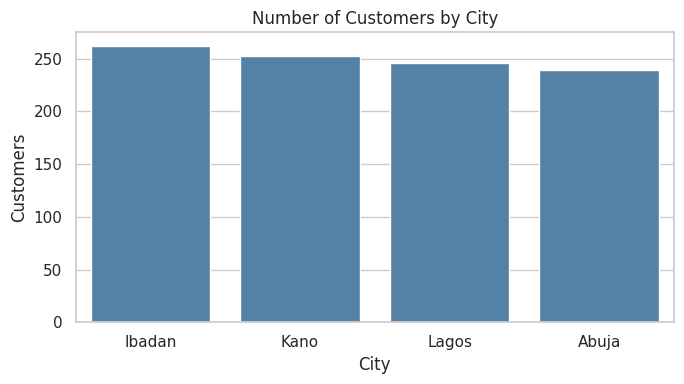

01 customers by city:
 City
Ibadan    262
Kano      253
Lagos     246
Abuja     239


In [57]:
# Customers by city
city_counts = customers["City"].astype(str).value_counts()
plt.figure(figsize=(7, 4))
sns.barplot(x=city_counts.index, y=city_counts.values, color="steelblue")
finish_chart("01_customers_by_city.png", "Number of Customers by City", "City", "Customers")
print("01 customers by city:\n", city_counts.to_string())



**Interpretation:** The 1,000 customers are spread almost evenly across four cities: Ibadan 262 (26.2%), Kano 253, Lagos 246 and Abuja 239 (23.9%). The gap between the largest and smallest city is only 23 customers.

**Business implication:** Demand is not concentrated in one market, so no city can be ignored. Ibadan has the largest customer base but no warehouse, so its customers are always served from another city.

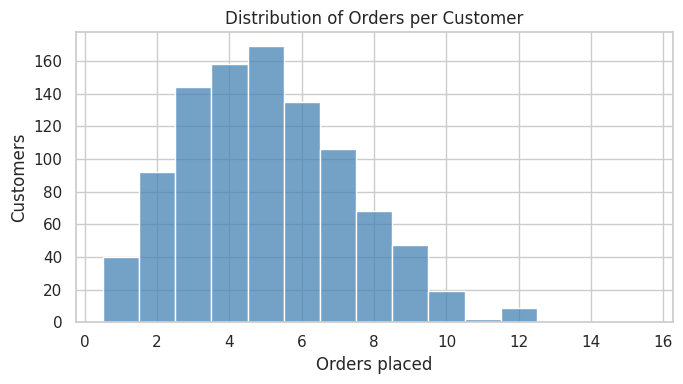


02 orders per customer: mean 5.05 | median 5.0 | max 15 | customers with 1 order: 40 | customers with 0 orders: 9


In [58]:
# Orders per customer
orders_per_customer = order_master.groupby("CustomerID").size()
plt.figure(figsize=(7, 4))
sns.histplot(orders_per_customer, discrete=True, color="steelblue")
finish_chart("02_orders_per_customer.png", "Distribution of Orders per Customer", "Orders placed", "Customers")
print("\n02 orders per customer: mean", round(orders_per_customer.mean(), 2),
      "| median", orders_per_customer.median(), "| max", orders_per_customer.max(),
      "| customers with 1 order:", int((orders_per_customer == 1).sum()),
      "| customers with 0 orders:", int(len(customers) - len(orders_per_customer)))



**Interpretation:** 991 of 1,000 customers placed at least one order, averaging 5.05 orders each (median 5, maximum 15). Only 40 customers (4%) ordered once, and 9 never ordered.

**Business implication:** Repeat buying is strong: about 96% of ordering customers bought more than once, a healthy retention signal. The 9 inactive customers and 40 one-time buyers are a small group for re-engagement, and the heaviest buyers (up to 15 orders) are candidates for the high-value segment in the segmentation section.

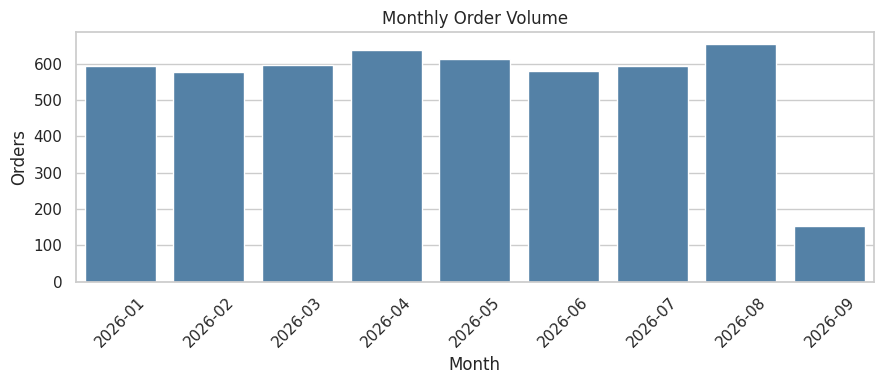


03 orders by month (September is partial, data ends 8 Sep):
 OrderYearMonth
2026-01    594
2026-02    577
2026-03    597
2026-04    638
2026-05    612
2026-06    579
2026-07    595
2026-08    654
2026-09    154


In [59]:
# Orders by month
monthly_orders = order_master.groupby("OrderYearMonth").size()
plt.figure(figsize=(9, 4))
sns.barplot(x=monthly_orders.index, y=monthly_orders.values, color="steelblue")
plt.xticks(rotation=45)
finish_chart("03_orders_by_month.png", "Monthly Order Volume", "Month", "Orders")
print("\n03 orders by month (September is partial, data ends 8 Sep):\n", monthly_orders.to_string())



**Interpretation:** Full months (January to August) ranged from 577 to 654 orders, averaging about 606. August was the peak (654, roughly 8% above average), followed by April (638). February was the lowest (577). September shows 154 orders in only 8 days, so its low bar reflects a partial month and not a decline.

**Business implication:** Demand is steady with only small peaks in April and August, so capacity can be planned around roughly constant monthly volume. With only 8 months of data and no earlier year, a true seasonal pattern cannot be confirmed.

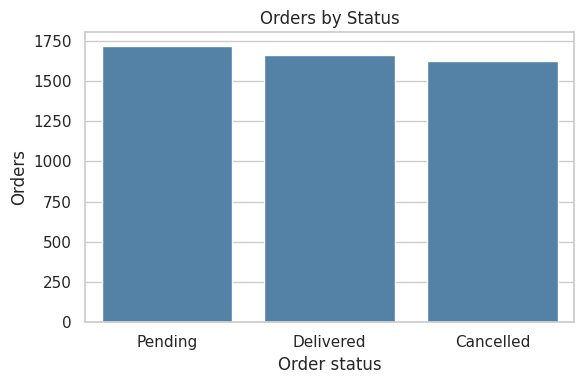


04 order status (%):
 OrderStatus
Pending      34.3
Delivered    33.2
Cancelled    32.5


In [60]:
# Order status
status_counts = order_master["OrderStatus"].astype(str).value_counts()
plt.figure(figsize=(6, 4))
sns.barplot(x=status_counts.index, y=status_counts.values, color="steelblue")
finish_chart("04_order_status.png", "Orders by Status", "Order status", "Orders")
print("\n04 order status (%):\n", (status_counts / status_counts.sum() * 100).round(1).to_string())



**Interpretation:** Orders divide almost exactly into thirds: Pending 34.3%, Delivered 33.2% and Cancelled 32.5%.

**Business implication:** Only a third of orders are delivered and nearly a third are cancelled, which is a serious fulfilment problem if the statuses are accurate. The 34% still Pending is also questionable, since the data spans 8 months and older orders should have been completed. Cancelled orders hold about a third of gross revenue (see section 2.2). How long orders stay pending should be investigated.

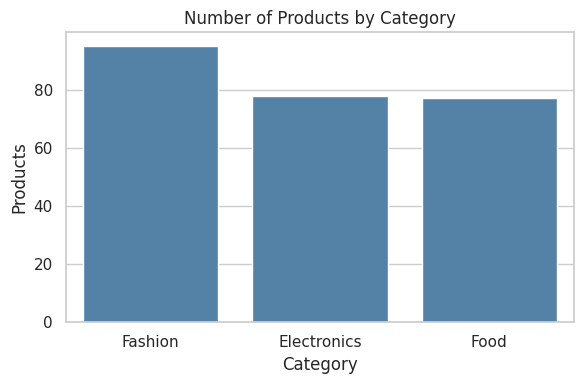


05 products by category:
 Category
Fashion        95
Electronics    78
Food           77


In [61]:
# Product categories
category_counts = products["Category"].astype(str).value_counts()
plt.figure(figsize=(6, 4))
sns.barplot(x=category_counts.index, y=category_counts.values, color="steelblue")
finish_chart("05_products_by_category.png", "Number of Products by Category", "Category", "Products")
print("\n05 products by category:\n", category_counts.to_string())



**Interpretation:** Of 250 products, Fashion has 95 (38%), Electronics 78 (31.2%) and Food 77 (30.8%).

**Business implication:** The catalogue leans towards Fashion, but the number of products might not equal sales. Further bivariate analysis to be conducted.

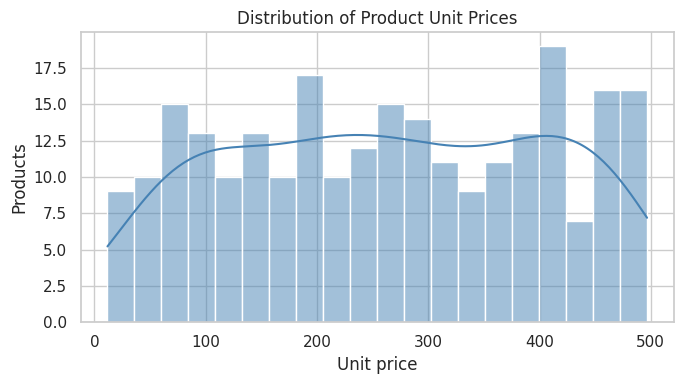


06 unit price: mean 264.2 | median 263.6 | min 11.78 | max 496.61


In [62]:
# Unit price
plt.figure(figsize=(7, 4))
sns.histplot(products["UnitPrice"], bins=20, kde=True, color="steelblue")
finish_chart("06_unit_price_distribution.png", "Distribution of Product Unit Prices", "Unit price", "Products")
print("\n06 unit price: mean", round(products["UnitPrice"].mean(), 1),
      "| median", round(products["UnitPrice"].median(), 1),
      "| min", products["UnitPrice"].min(), "| max", products["UnitPrice"].max())



**Interpretation:** Unit prices range from 11.78 to 496.61, with a mean of 264.2 and a median of 263.6. The near-identical mean and median show a symmetric distribution with no extreme high-priced items.

**Business implication:** The catalogue covers the full price range and not a niche, and prices are not a source of outliers. Revenue will therefore be driven more by quantities ordered and product mix than by a few premium items.

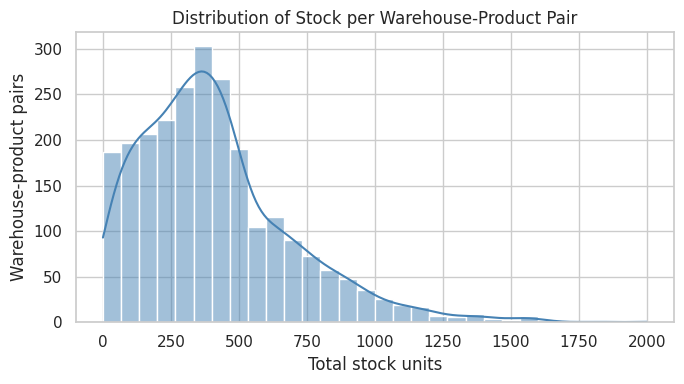


07 stock per pair: mean 410.5 | median 364.0 | pairs with stock under 100: 264 of 2455


In [63]:
# Inventory stock
plt.figure(figsize=(7, 4))
sns.histplot(inventory["Stock"], bins=30, kde=True, color="steelblue")
finish_chart("07_inventory_stock_distribution.png",
             "Distribution of Stock per Warehouse-Product Pair", "Total stock units", "Warehouse-product pairs")
print("\n07 stock per pair: mean", round(inventory["Stock"].mean(), 1),
      "| median", inventory["Stock"].median(),
      "| pairs with stock under 100:", int((inventory["Stock"] < 100).sum()),
      "of", len(inventory))



In [64]:
shipped_lines = item_master[["WarehouseID", "ProductID"]].drop_duplicates()
stocked_pairs = inventory[["WarehouseID", "ProductID"]].drop_duplicates()
check = shipped_lines.merge(stocked_pairs, on=["WarehouseID", "ProductID"], how="left", indicator=True)
share_not_stocked = (check["_merge"] == "left_only").mean() * 100
print(f"{share_not_stocked:.1f}% of shipped warehouse-product pairs had no inventory record")

34.4% of shipped warehouse-product pairs had no inventory record


**Interpretation:** Stock per warehouse-product pair averages 410.5 against a median of 364, a right-skewed distribution in which some pairs hold much more stock than the rest. 264 of 2,455 pairs (10.8%) hold fewer than 100 units.

Not every warehouse-product combination has an inventory record: 2,455 of the 3,750 possible pairs (15 warehouses x 250 products) do, so 1,295 pairs (34.5%) have none. A cross-check against shipments shows that 34.4% of the warehouse-product pairs that actually shipped also had no inventory record, almost exactly the share expected if shipments ignored inventory.

**Business implication:** About one in ten stocked pairs is at risk of running out (using an assumed threshold of 100 units, since no reorder level was provided). More importantly, inventory records do not line up with shipping activity: a third of shipped items have no record in the dispatching warehouse. Either the inventory data is incomplete, or orders are being fulfilled from warehouses that do not hold the product. Both possibilities weaken stock visibility and should be investigated before inventory figures are used for replenishment decisions.

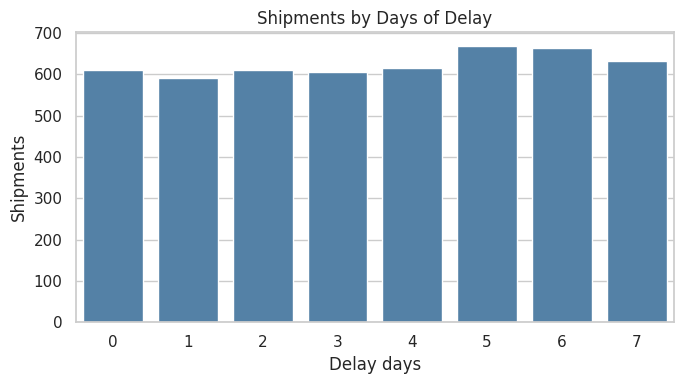


08 delay days: mean 3.57 | share delayed (3+ days): 63.7 %
DelayDays
0    611
1    592
2    611
3    605
4    616
5    668
6    664
7    633


In [65]:
# Delay days
plt.figure(figsize=(7, 4))
sns.countplot(x="DelayDays", data=order_master, color="steelblue")
finish_chart("08_delay_days_distribution.png", "Shipments by Days of Delay", "Delay days", "Shipments")
print("\n08 delay days: mean", round(order_master["DelayDays"].mean(), 2),
      "| share delayed (3+ days):", round(order_master["IsDelayed"].mean() * 100, 1), "%")
print(order_master["DelayDays"].value_counts().sort_index().to_string())



**Interpretation:** Delay is spread almost evenly across 0 to 7 days, with 592 to 668 shipments at each value (about 12.5% each). The mean delay is 3.57 days and 63.7% of shipments are delayed (3+ days), which is what an even spread would produce (5 of 8 values = 62.5%). Days 5 (668) and 6 (664) are slightly the most common.

**Business implication:** Delays are not occasional exceptions: nearly two in three shipments arrive 3 or more days late, with no typical delay length. That points to a systemic process problem and not isolated incidents. Even shipments classed as On Time can be up to 2 days late, so the on-time definition is generous. Delivery delay is the first KPI needing management attention.

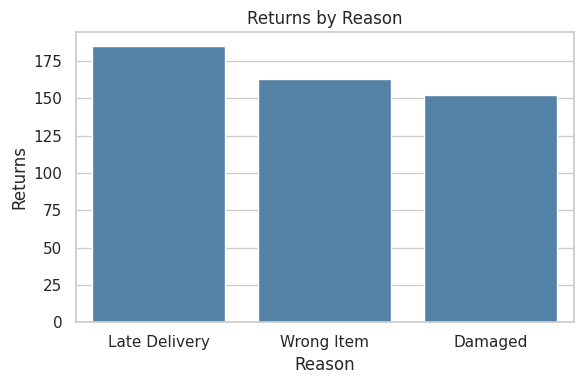


09 return reasons:
 Reason
Late Delivery    185
Wrong Item       163
Damaged          152


In [66]:
# Return reasons
reason_counts = returns["Reason"].astype(str).value_counts()
plt.figure(figsize=(6, 4))
sns.barplot(x=reason_counts.index, y=reason_counts.values, color="steelblue")
finish_chart("09_return_reasons.png", "Returns by Reason", "Reason", "Returns")
print("\n09 return reasons:\n", reason_counts.to_string())



**Interpretation:** Of 500 returns, Late Delivery accounts for 185 (37.0%), Wrong Item 163 (32.6%) and Damaged 152 (30.4%).

**Business implication:** Late delivery is the largest single return reason, linking delivery performance directly to returns and customer dissatisfaction, and it is addressable through delivery improvements. Wrong Item (picking accuracy) and Damaged (handling and packaging) together make up 63% of returns and point to warehouse quality control. The bivariate analysis will test whether delayed orders actually have more returns.

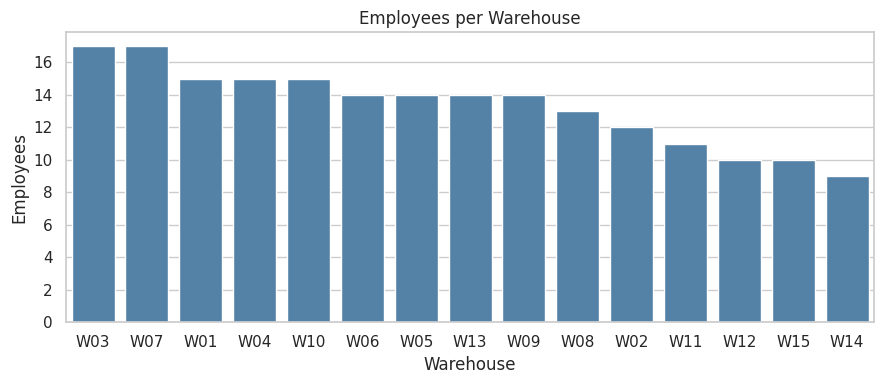


10 employees per warehouse:
 WarehouseID
W03    17
W07    17
W01    15
W04    15
W10    15
W06    14
W05    14
W13    14
W09    14
W08    13
W02    12
W11    11
W12    10
W15    10
W14     9


In [67]:
# Employees per warehouse
employees_per_warehouse = employees.groupby("WarehouseID").size().sort_values(ascending=False)
plt.figure(figsize=(9, 4))
sns.barplot(x=employees_per_warehouse.index, y=employees_per_warehouse.values, color="steelblue")
finish_chart("10_employees_per_warehouse.png", "Employees per Warehouse", "Warehouse", "Employees")
print("\n10 employees per warehouse:\n", employees_per_warehouse.to_string())



**Interpretation:** The 200 employees are spread unevenly across 15 warehouses, from 9 to 17 per warehouse (average 13.3). W03 and W07 have the most (17 each), while W14 has only 9 and W12 and W15 have 10 each.

**Business implication:** The largest team is nearly double the smallest. Whether this is justified depends on workload, which is examined with chart 11.

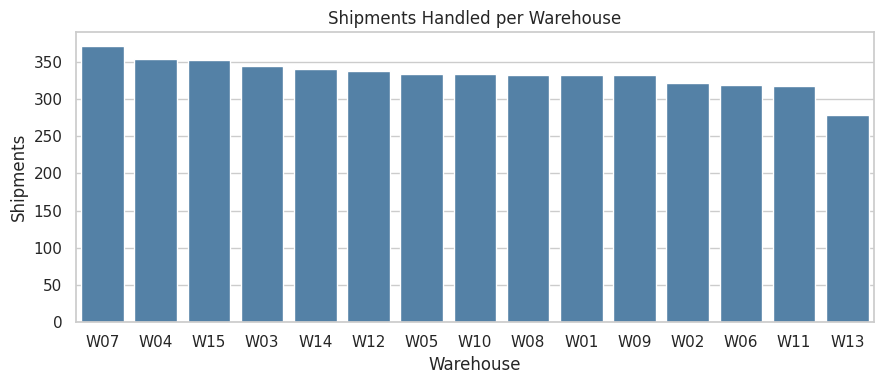


11 shipments per warehouse:
 WarehouseID
W07    371
W04    354
W15    352
W03    344
W14    340
W12    337
W05    334
W10    334
W08    332
W01    332
W09    332
W02    322
W06    319
W11    318
W13    279


In [68]:
# Shipments per warehouse
shipments_per_warehouse = order_master.groupby("WarehouseID").size().sort_values(ascending=False)
plt.figure(figsize=(9, 4))
sns.barplot(x=shipments_per_warehouse.index, y=shipments_per_warehouse.values, color="steelblue")
finish_chart("11_shipments_per_warehouse.png", "Shipments Handled per Warehouse", "Warehouse", "Shipments")
print("\n11 shipments per warehouse:\n", shipments_per_warehouse.to_string())



**Interpretation:** Shipments per warehouse average 333. W07 handles the most (371, about 11% above average) and W13 the fewest (279, about 16% below). Most warehouses fall between 318 and 354.

Combining charts 10 and 11 gives shipments per employee (company average: 25):

| Warehouse | Shipments | Employees | Shipments per employee |
|---|---|---|---|
| W14 | 340 | 9 | 37.8 |
| W15 | 352 | 10 | 35.2 |
| W12 | 337 | 10 | 33.7 |
| W13 | 279 | 14 | 19.9 |
| W03 | 344 | 17 | 20.2 |

**Business implication:** Shipment volume is fairly balanced, but staffing is not. W14, W15 and W12 carry about 35% to 50% more shipments per employee than average, while W13 and W03 carry about 20% less. This is an early sign of workload imbalance and a candidate explanation for delays, to be tested in the bivariate analysis. Staff could be rebalanced from lightly loaded warehouses to the heavily loaded ones.

In [69]:
# Suppliers
print("\nSuppliers:", len(cleaned["suppliers"]), "records with only an ID and a name; no variable to analyse.")


Suppliers: 150 records with only an ID and a name; no variable to analyse.


**Suppliers:** The suppliers table holds 150 records with only an ID and a name. With no performance variable and no link to any other table, no univariate analysis is possible.

## 3.1 Summary of Univariate Findings

1. **Demand is steady and evenly spread** across cities and months, with only small peaks in April and August.
2. **Customers are loyal:** about 96% of ordering customers bought more than once.
3. **Fulfilment is weak:** only 33% of orders are delivered, 32.5% are cancelled and 34% remain pending.
4. **Delays are systemic:** 63.7% of shipments are 3+ days late, spread evenly across 0 to 7 days.
5. **Late delivery is the top return reason** (37%).
6. **Staffing is uneven relative to workload:** W14, W15 and W12 handle the most shipments per employee.
7. **About 35% of warehouse-product combinations have no inventory record,** and about 11% of stocked pairs are below 100 units.

**Caution:** Many distributions here are unusually even, which suggests the data may be simulated. Small differences between categories should not be over-interpreted, and several later tests may show no significant difference.

In [70]:
# ---------- 0. Make sure the data and helper are available ----------
if "cleaned" not in globals():
    cleaned = {os.path.basename(f).replace("_clean.csv", ""): pd.read_csv(f)
               for f in glob.glob(CLEAN + "*_clean.csv")}
order_master = pd.read_csv(CLEAN + "order_master.csv", parse_dates=["OrderDate"])
item_master = pd.read_csv(CLEAN + "item_master.csv", parse_dates=["OrderDate"])

def finish_chart(file_name, title, xlabel, ylabel):
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.savefig(CHARTS + file_name, dpi=150, bbox_inches="tight")
    plt.show()

net_orders = order_master[order_master["CountsAsNetRevenue"] == 1]
net_items = item_master[item_master["CountsAsNetRevenue"] == 1]

print("Supplier vs delivery performance: NOT POSSIBLE (suppliers table has no link to any other table)\n")



Supplier vs delivery performance: NOT POSSIBLE (suppliers table has no link to any other table)



## 3.2 Bivariate Analysis

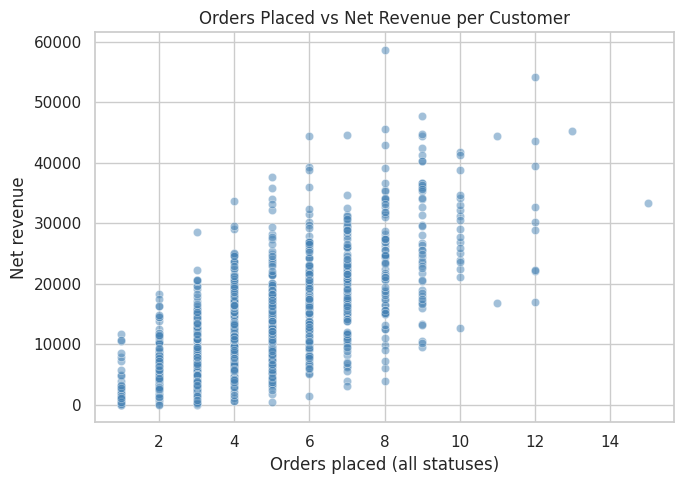

12 correlation orders vs net revenue: 0.67
   top 10% of customers share of net revenue: 23.9 %
   top 5 customers:
 CustomerID  AllOrders  NetRevenue
     C0223          8     58660.0
     C0773         12     54174.0
     C0807          9     47670.0
     C0599          8     45623.0
     C0880         13     45311.0


In [71]:
# Customer: orders vs net revenue
customer_summary = (net_orders.groupby("CustomerID")
                    .agg(NetOrders=("OrderID", "count"), NetRevenue=("OrderRevenue", "sum"))
                    .reset_index())
all_orders_per_customer = order_master.groupby("CustomerID").size().rename("AllOrders")
customer_summary = customer_summary.merge(all_orders_per_customer, on="CustomerID")
plt.figure(figsize=(7, 5))
sns.scatterplot(data=customer_summary, x="AllOrders", y="NetRevenue", alpha=0.5, color="steelblue")
finish_chart("12_customer_orders_vs_revenue.png", "Orders Placed vs Net Revenue per Customer",
             "Orders placed (all statuses)", "Net revenue")
print("12 correlation orders vs net revenue:", round(customer_summary["AllOrders"].corr(customer_summary["NetRevenue"]), 2))
print("   top 10% of customers share of net revenue:",
      round(customer_summary.nlargest(100, "NetRevenue")["NetRevenue"].sum() / customer_summary["NetRevenue"].sum() * 100, 1), "%")
print("   top 5 customers:\n", customer_summary.nlargest(5, "NetRevenue")[["CustomerID", "AllOrders", "NetRevenue"]].round(0).to_string(index=False))



**Chart 12: Orders placed vs net revenue per customer**

**Interpretation:** Customers who place more orders generate more net revenue (correlation 0.67), but the link is only moderate because order values and cancellations vary. C0773 placed 12 orders and earned 54,174, while C0223 placed 8 orders and earned 58,660, the highest in the business. Revenue is not concentrated: the top 10% of customers (100 customers) generate 23.9% of net revenue, and the largest single customer accounts for only about 0.4%.

**Business implication:** SwiftLog does not depend on a few large accounts, which lowers risk, but there is also no small group of "VIP" customers to protect. Customer value depends on both how often customers buy and how large each order is. The top five customers (C0223, C0773, C0807, C0599, C0880) are natural candidates for a priority-account programme.

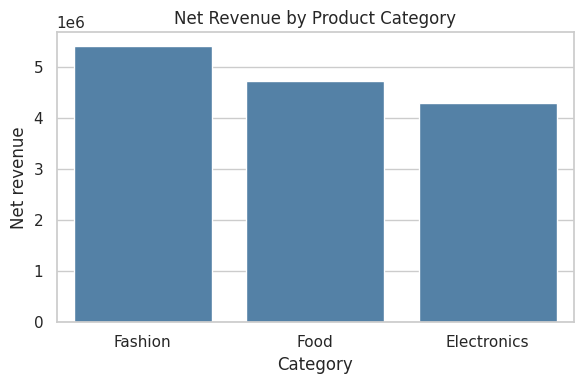


13 net revenue by category:
 Category
Fashion        5413030.0
Food           4736753.0
Electronics    4289435.0
   share %:
 Category
Fashion        37.5
Food           32.8
Electronics    29.7


In [72]:
# Net revenue by category
category_revenue = net_items.groupby("Category")["LineRevenue"].sum().sort_values(ascending=False)
plt.figure(figsize=(6, 4))
sns.barplot(x=category_revenue.index, y=category_revenue.values, color="steelblue")
finish_chart("13_net_revenue_by_category.png", "Net Revenue by Product Category", "Category", "Net revenue")
print("\n13 net revenue by category:\n", category_revenue.round(0).to_string())
print("   share %:\n", (category_revenue / category_revenue.sum() * 100).round(1).to_string())



**Chart 13: Net revenue by product category**

**Interpretation:** Fashion earns the most net revenue (5.41M, 37.5%), followed by Food (4.74M, 32.8%) and Electronics (4.29M, 29.7%). Comparing each category's revenue share with its share of the catalogue: Fashion holds 38.0% of products and 37.5% of revenue (proportional), Food holds 30.8% of products but 32.8% of revenue, and Electronics holds 31.2% of products but only 29.7% of revenue.

**Business implication:** Fashion leads mainly because it has the largest range, not because each product performs better. Food earns more than its size suggests and Electronics slightly less, but the gaps are modest.

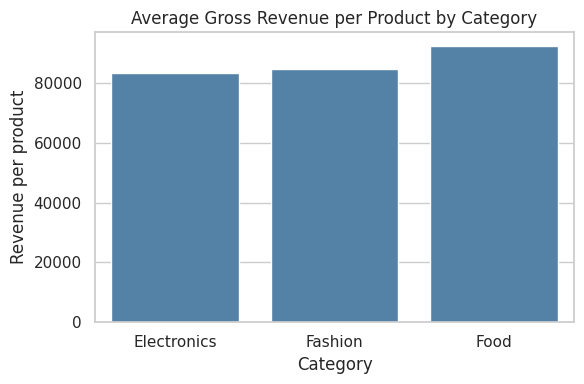


14 category detail:
              Products  Units  GrossRevenue  RevenuePerProduct
Category                                                     
Electronics        78  25154     6495061.0            83270.0
Fashion            95  31715     8059603.0            84838.0
Food               77  25573     7113402.0            92382.0


In [73]:
# Category: revenue per product and units
category_detail = item_master.groupby("Category").agg(
    Products=("ProductID", "nunique"), Units=("Quantity", "sum"), GrossRevenue=("LineRevenue", "sum"))
category_detail["RevenuePerProduct"] = category_detail["GrossRevenue"] / category_detail["Products"]
plt.figure(figsize=(6, 4))
sns.barplot(x=category_detail.index, y=category_detail["RevenuePerProduct"], color="steelblue")
finish_chart("14_revenue_per_product_by_category.png", "Average Gross Revenue per Product by Category",
             "Category", "Revenue per product")
print("\n14 category detail:\n", category_detail.round(0).to_string())



**Chart 14: Average gross revenue per product by category**

*This chart uses gross revenue (all orders, including Cancelled) so that products are compared on everything customers ordered.*

**Interpretation:** Food earns the most revenue per product (92,382), ahead of Fashion (84,838) and Electronics (83,270), a spread of about 11%. Fashion sells the most units (31,715 vs about 25,000 for each of the others), but Food earns more per unit sold (about 278 vs 254 for Fashion and 258 for Electronics), so Food's advantage comes from the value of what it sells, not from volume.

**Business implication:** Food is the most productive category per product, so extending the Food range or promoting it is worth testing. Fashion's total lead comes from having 95 products, not from stronger products.

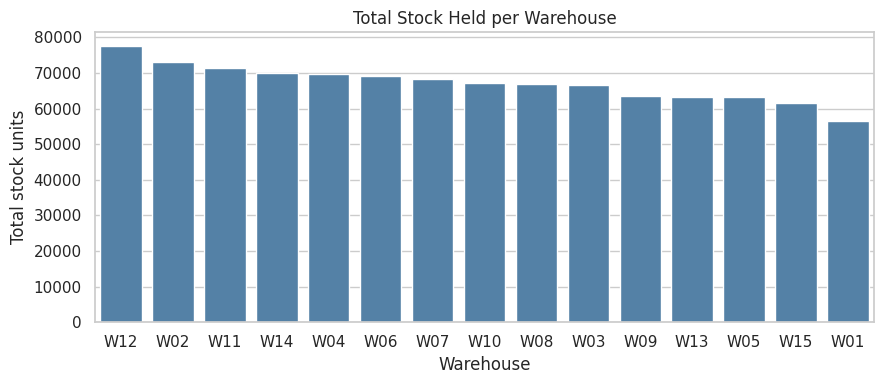


15 stock per warehouse:
              TotalStock  UniqueProducts
WarehouseID                            
W12               77517             174
W02               73012             169
W11               71439             163
W14               69883             164
W04               69696             167
W06               69177             164
W07               68338             170
W10               67169             157
W08               66971             159
W03               66559             170
W09               63604             157
W13               63211             162
W05               63125             163
W15               61524             162
W01               56539             154


In [74]:
# Inventory per warehouse
inventory = cleaned["inventory"]
warehouse_stock = inventory.groupby("WarehouseID").agg(
    TotalStock=("Stock", "sum"), UniqueProducts=("ProductID", "nunique")).sort_values("TotalStock", ascending=False)
plt.figure(figsize=(9, 4))
sns.barplot(x=warehouse_stock.index, y=warehouse_stock["TotalStock"], color="steelblue")
finish_chart("15_stock_per_warehouse.png", "Total Stock Held per Warehouse", "Warehouse", "Total stock units")
print("\n15 stock per warehouse:\n", warehouse_stock.to_string())



**Chart 15: Total stock held per warehouse**

**Interpretation:** Stock held ranges from 56,539 units at W01 to 77,517 at W12 (average about 67,200), so W12 holds about 15% above average and W01 about 16% below. Products stocked per warehouse range from 154 (W01) to 174 (W12) out of 250. W12 and W01 shipped almost the same number of orders (337 and 332), yet W12 holds about 230 units per shipment and W01 about 170.

**Business implication:** Stock is not distributed in line with demand. W12 ties up more inventory than its volume needs, while W01 is the thinnest and most exposed to stock-outs. Rebalancing stock towards warehouses with low stock per shipment could cut holding costs and shortages. This is indicative only, because inventory records are incomplete.

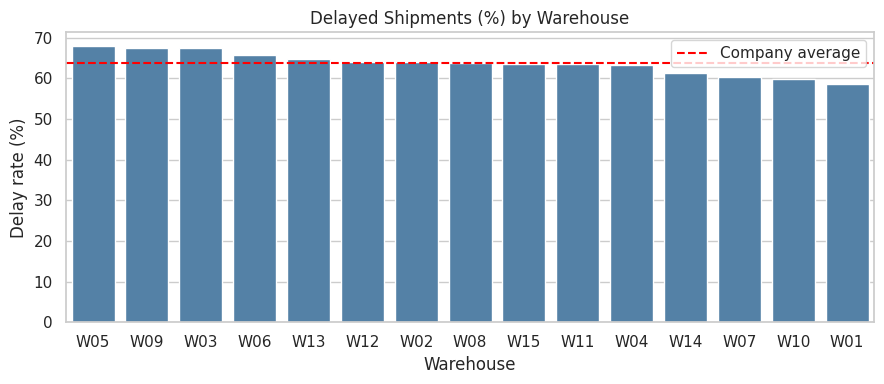


16 delay rate by warehouse (company avg 63.7 %):
              Shipments  DelayRate  AvgDelay
WarehouseID                                
W05                334       68.0      3.79
W09                332       67.5      3.68
W03                344       67.4      3.68
W06                319       65.8      3.61
W13                279       64.9      3.61
W12                337       64.1      3.59
W02                322       64.0      3.44
W08                332       63.9      3.67
W15                352       63.6      3.49
W11                318       63.5      3.44
W04                354       63.3      3.52
W14                340       61.5      3.63
W07                371       60.4      3.47
W10                334       59.9      3.49
W01                332       58.7      3.46


In [75]:
# Delay rate by warehouse
warehouse_delay = (order_master.groupby("WarehouseID")
                   .agg(Shipments=("OrderID", "count"), DelayRate=("IsDelayed", "mean"), AvgDelay=("DelayDays", "mean"))
                   .sort_values("DelayRate", ascending=False))
plt.figure(figsize=(9, 4))
sns.barplot(x=warehouse_delay.index, y=warehouse_delay["DelayRate"] * 100, color="steelblue")
plt.axhline(order_master["IsDelayed"].mean() * 100, color="red", linestyle="--", label="Company average")
plt.legend()
finish_chart("16_delay_rate_by_warehouse.png", "Delayed Shipments (%) by Warehouse", "Warehouse", "Delay rate (%)")
print("\n16 delay rate by warehouse (company avg", round(order_master["IsDelayed"].mean() * 100, 1), "%):\n",
      (warehouse_delay.assign(DelayRate=lambda d: (d["DelayRate"] * 100).round(1), AvgDelay=lambda d: d["AvgDelay"].round(2))).to_string())

**Chart 16: Delayed shipments (%) by warehouse**

**Interpretation:** Every warehouse delays more than half its shipments, from 58.7% at W01 to 68.0% at W05 (company average 63.7%). W05 also has the longest average delay (3.79 days), followed by W09 and W03 (67.4% to 67.5%). The lowest rates are at W01, W10 (59.9%) and W07 (60.4%), and W07 achieves this while handling the most shipments (371). With about 330 shipments per warehouse, differences of around 5 points can easily arise by chance, and the best-to-worst spread is roughly what chance alone would produce for 15 warehouses.

**Business implication:** Delay is a company-wide problem, not the fault of a few poor warehouses. W01, W10 and W07 are the most efficient on this measure and their processes are worth studying, but no warehouse is performing well. Staffing does not explain the pattern either: W03 and W07 both have the largest teams (17), yet W03 is among the worst and W07 among the best.

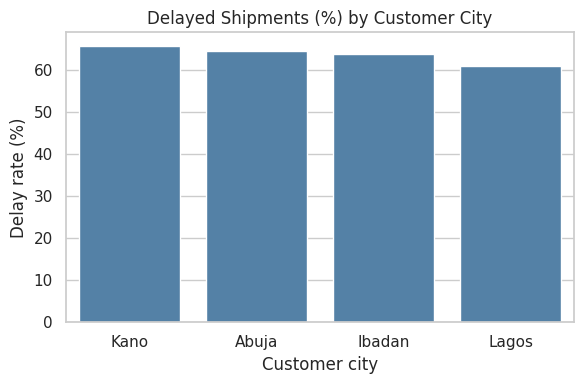


17 delay rate by customer city (%):
 CustomerCity
Kano      65.7
Abuja     64.4
Ibadan    63.8
Lagos     61.0


In [76]:
# Delay rate by customer city
city_delay = order_master.groupby("CustomerCity")["IsDelayed"].mean().sort_values(ascending=False) * 100
plt.figure(figsize=(6, 4))
sns.barplot(x=city_delay.index, y=city_delay.values, color="steelblue")
finish_chart("17_delay_rate_by_customer_city.png", "Delayed Shipments (%) by Customer City", "Customer city", "Delay rate (%)")
print("\n17 delay rate by customer city (%):\n", city_delay.round(1).to_string())

**Chart 17: Delayed shipments (%) by customer city**

**Interpretation:** Kano customers see the highest delay rate (65.7%), then Abuja (64.4%) and Ibadan (63.8%), while Lagos is lowest (61.0%). The Lagos-to-Kano gap is 4.7 points, on roughly 1,250 orders per city. Ibadan, which has no warehouse of its own, performs in line with the other cities.

**Business implication:** Delays are high everywhere and differences between cities are small. Since Ibadan customers are not worse off for lacking a local warehouse, opening a warehouse there is not justified by delivery performance alone.

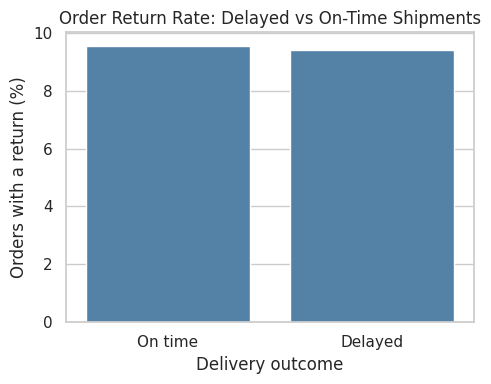


18 return rate (%):
 On time    9.54
Delayed    9.42


In [77]:
# Return rate: delayed vs on time
return_by_delay = order_master.groupby("IsDelayed")["HasReturn"].mean() * 100
return_by_delay.index = ["On time", "Delayed"]
plt.figure(figsize=(5, 4))
sns.barplot(x=return_by_delay.index, y=return_by_delay.values, color="steelblue")
finish_chart("18_return_rate_delayed_vs_on_time.png", "Order Return Rate: Delayed vs On-Time Shipments",
             "Delivery outcome", "Orders with a return (%)")
print("\n18 return rate (%):\n", return_by_delay.round(2).to_string())

**Chart 18: Order return rate, delayed vs on-time shipments**

**Interpretation:** Orders with delayed shipments are returned at 9.42%, and orders delivered on time at 9.54%. The two are essentially identical.

**Business implication:** Delivery delay does not make a return more likely in this data. Overall about 9.5% of orders have a return regardless of how delivery went, so reducing delays will not by itself reduce returns.

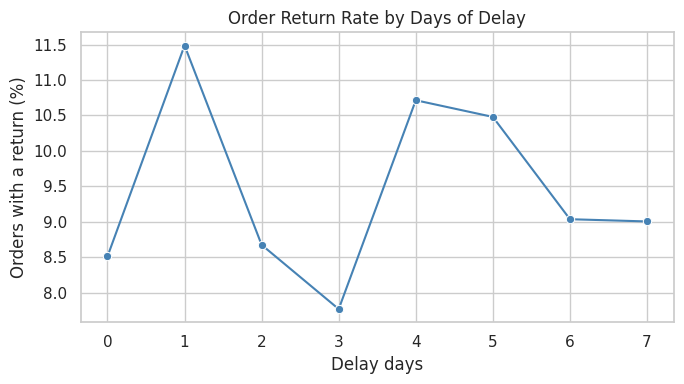


19 return rate by delay days (%):
 DelayDays
0     8.51
1    11.49
2     8.67
3     7.77
4    10.71
5    10.48
6     9.04
7     9.00
   correlation DelayDays vs HasReturn: -0.0


In [78]:
# Return rate by delay days
return_by_days = order_master.groupby("DelayDays")["HasReturn"].mean() * 100
plt.figure(figsize=(7, 4))
sns.lineplot(x=return_by_days.index, y=return_by_days.values, marker="o", color="steelblue")
finish_chart("19_return_rate_by_delay_days.png", "Order Return Rate by Days of Delay", "Delay days", "Orders with a return (%)")
print("\n19 return rate by delay days (%):\n", return_by_days.round(2).to_string())
print("   correlation DelayDays vs HasReturn:", round(order_master["DelayDays"].corr(order_master["HasReturn"]), 3))

**Chart 19: Order return rate by days of delay**

**Interpretation:** The return rate moves between 7.8% (3 days) and 11.5% (1 day) with no trend, and the correlation between delay days and returns is effectively zero. Each delay-day group has roughly 600 orders, so swings of about 2 points are within normal chance variation.

**Business implication:** A longer delay does not lead to more returns, so there is no delay threshold at which returns start to rise. Returns need to be explained by other factors, such as picking errors and damage. A check on whether "Late Delivery" returns actually come from late orders follows below.

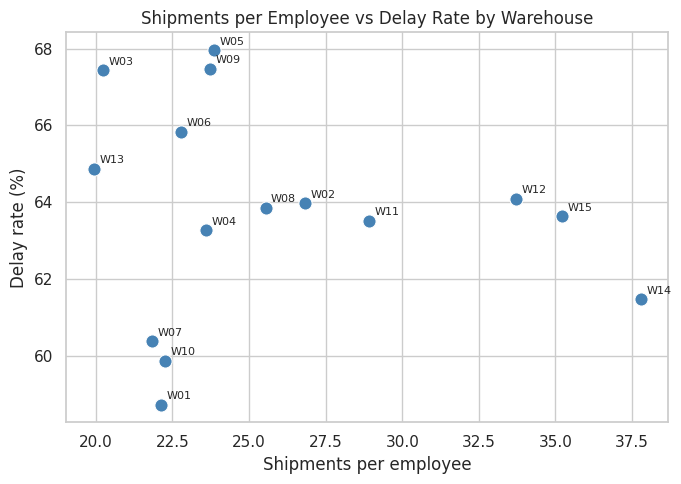


20 correlation workload vs delay rate: -0.13


In [79]:
# Warehouse workload vs delay rate
employees = cleaned["employees"]
workload = warehouse_delay.join(employees.groupby("WarehouseID").size().rename("Employees"))
workload["ShipmentsPerEmployee"] = workload["Shipments"] / workload["Employees"]
plt.figure(figsize=(7, 5))
sns.scatterplot(data=workload, x="ShipmentsPerEmployee", y=workload["DelayRate"] * 100, s=90, color="steelblue")
for warehouse, row in workload.iterrows():
    plt.annotate(warehouse, (row["ShipmentsPerEmployee"], row["DelayRate"] * 100), xytext=(4, 4), textcoords="offset points", fontsize=8)
finish_chart("20_workload_vs_delay_rate.png", "Shipments per Employee vs Delay Rate by Warehouse",
             "Shipments per employee", "Delay rate (%)")
print("\n20 correlation workload vs delay rate:", round(workload["ShipmentsPerEmployee"].corr(workload["DelayRate"]), 2))

**Chart 20: Shipments per employee vs delay rate by warehouse**

**Interpretation:** Across the 15 warehouses the correlation between workload (shipments per employee) and delay rate is -0.13, which is weak and slightly in the opposite direction to expectation. The warehouses carrying the heaviest load, W14 (37.8 shipments per employee), W15 (35.2) and W12 (33.7), delay 61.5%, 63.6% and 64.1% of shipments, at or below the company average.

**Business implication:** The workload-imbalance explanation proposed after chart 11 is not supported. Delays are not caused by understaffed warehouses, so adding staff is unlikely to fix them on its own. Causes must lie in processes the data does not capture, such as dispatch handling, carrier performance or order processing time.

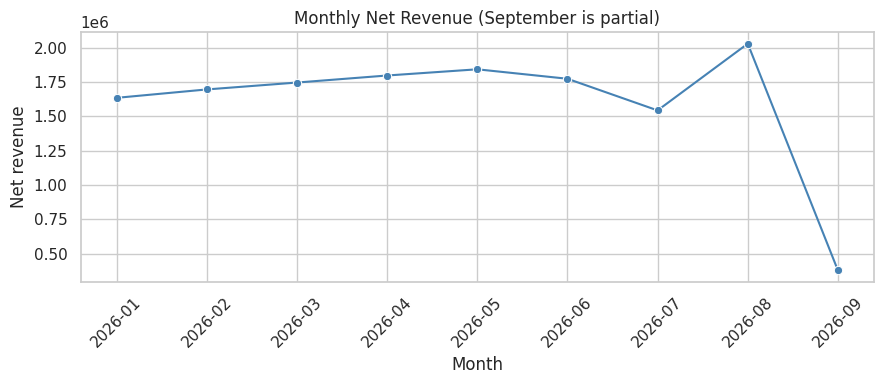


21 monthly net revenue:
 OrderYearMonth
2026-01    1634489.0
2026-02    1695572.0
2026-03    1745715.0
2026-04    1796923.0
2026-05    1842002.0
2026-06    1773301.0
2026-07    1543140.0
2026-08    2028408.0
2026-09     379668.0


In [80]:
# Monthly net revenue
monthly_revenue = net_orders.groupby("OrderYearMonth")["OrderRevenue"].sum()
plt.figure(figsize=(9, 4))
sns.lineplot(x=monthly_revenue.index, y=monthly_revenue.values, marker="o", color="steelblue")
plt.xticks(rotation=45)
finish_chart("21_monthly_net_revenue.png", "Monthly Net Revenue (September is partial)", "Month", "Net revenue")
print("\n21 monthly net revenue:\n", monthly_revenue.round(0).to_string())

**Chart 21: Monthly net revenue**

*September is a partial month (data ends 8 Sep) and is not comparable.*

**Interpretation:** Net revenue rose steadily from 1.63M in January to 1.84M in May (+12.7%), dipped to 1.77M in June and 1.54M in July (the lowest full month, 12% below the January-to-August average of about 1.76M), then jumped to 2.03M in August (the peak, +31% on July and about 15% above average). Peak months by order count are August (654) and April (638), and by revenue August and May.

**Business implication:** Revenue is more volatile than order volume. July had a near-average 595 orders yet the lowest revenue, so its dip came from lower order values or more cancellations, not fewer customers, which is worth investigating. August is the business's strongest month, and the July-to-August swing is large enough to affect stock and capacity planning.

# 3.3 Multivariate Analysis

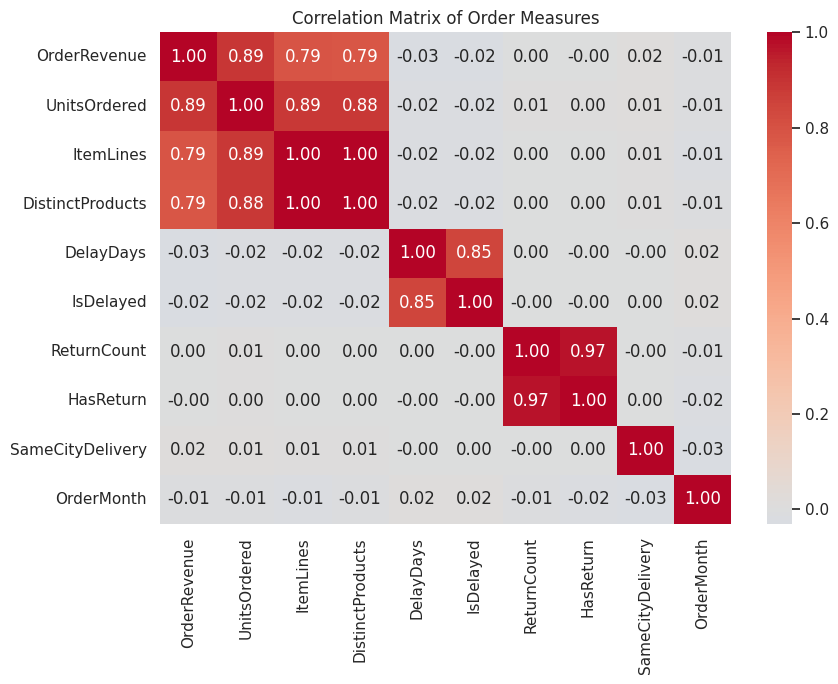


22 strongest correlations (excluding obvious pairs):
OrderRevenue      UnitsOrdered        0.888
                  ItemLines           0.787
                  DistinctProducts    0.786
SameCityDelivery  OrderMonth         -0.030
OrderRevenue      DelayDays          -0.026
                  IsDelayed          -0.025


In [81]:
# ================= MULTIVARIATE =================

# Correlation heatmap
numeric_columns = ["OrderRevenue", "UnitsOrdered", "ItemLines", "DistinctProducts", "DelayDays",
                   "IsDelayed", "ReturnCount", "HasReturn", "SameCityDelivery", "OrderMonth"]
correlation = order_master[numeric_columns].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0)
finish_chart("22_correlation_heatmap.png", "Correlation Matrix of Order Measures", "", "")
pairs = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool)).stack()
print("\n22 strongest correlations (excluding obvious pairs):")
obvious = {("DelayDays", "IsDelayed"), ("ReturnCount", "HasReturn"), ("UnitsOrdered", "ItemLines"),
           ("ItemLines", "DistinctProducts"), ("UnitsOrdered", "DistinctProducts")}
print(pairs[[pair not in obvious and pair[::-1] not in obvious for pair in pairs.index]]
      .sort_values(key=abs, ascending=False).head(6).round(3).to_string())

**Chart 22: Correlation matrix of order measures**

**Interpretation:** Only revenue-related measures are meaningfully correlated. Order revenue is strongly linked to units ordered (0.89) and moderately to the number of item lines (0.79) and distinct products (0.79), so about 79% of the variation in order revenue is explained by the number of units alone. Every other pair is close to zero: revenue vs delay days (-0.03), revenue vs delayed flag (-0.03), and same-city delivery vs month (-0.03).

**Business implication:** Order value is driven by basket size. Delivery delay, returns and shipping distance are unrelated to revenue and to each other. This is useful for later modelling, since basket measures are good predictors of order value, while delay and returns will be difficult to predict from the variables available in this data.

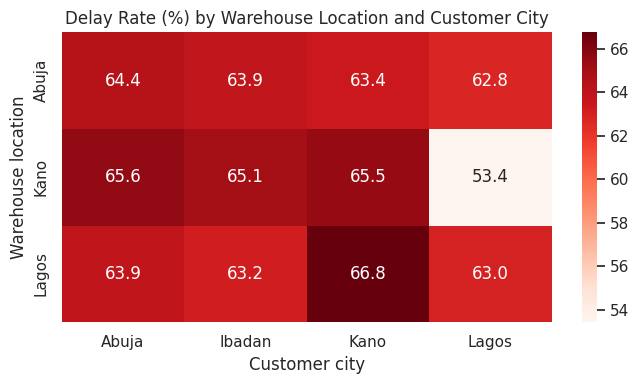


23 delay rate by route (%):
 CustomerCity       Abuja  Ibadan  Kano  Lagos
WarehouseLocation                            
Abuja               64.4    63.9  63.4   62.8
Kano                65.6    65.1  65.5   53.4
Lagos               63.9    63.2  66.8   63.0


In [82]:
# Delay rate: warehouse location x customer city
route_delay = order_master.pivot_table(index="WarehouseLocation", columns="CustomerCity",
                                       values="IsDelayed", aggfunc="mean") * 100
plt.figure(figsize=(7, 4))
sns.heatmap(route_delay, annot=True, fmt=".1f", cmap="Reds")
finish_chart("23_delay_rate_by_route.png", "Delay Rate (%) by Warehouse Location and Customer City",
             "Customer city", "Warehouse location")
print("\n23 delay rate by route (%):\n", route_delay.round(1).to_string())

**Chart 23: Delay rate by warehouse location and customer city**

**Interpretation:** Most routes sit between 62.8% and 66.8%. The standout is Kano warehouses serving Lagos customers at 53.4%, about 10 points below the company average of 63.7%. This route has 249 orders (about 133 delayed against about 159 expected), so it is not a small sample, and the gap is large enough that chance is an unlikely explanation even after allowing for 12 routes being compared. The highest rates are Lagos warehouses to Kano customers (66.8%), Kano to Abuja (65.6%) and Kano to Kano (65.5%).

Order volumes by route:

| Warehouse location | Abuja | Ibadan | Kano | Lagos | Total |
|---|---|---|---|---|---|
| Abuja | 320 | 335 | 328 | 352 | 1,335 |
| Kano | 250 | 261 | 258 | 249 | 1,018 |
| Lagos | 635 | 644 | 701 | 667 | 2,647 |

**Business implication:** Route does not systematically drive delay: same-city routes are not faster (consistent with section 2.4). The Kano-to-Lagos route is the exception and the only one worth investigating, since whatever is working there (carrier, dispatch process, timing) could be copied to other routes. Note the route has no obvious logistical advantage, which makes the cause more likely to be operational than geographic.

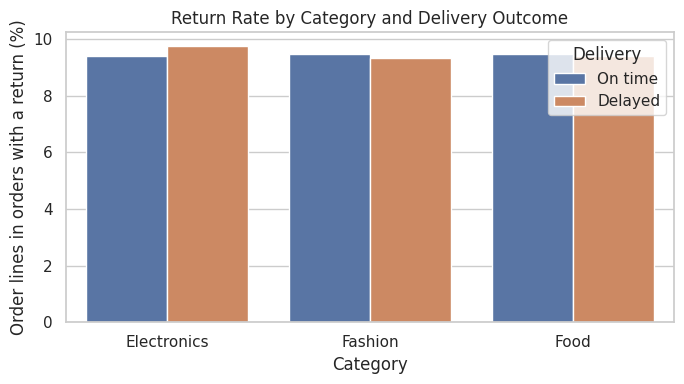


24 return rate by category and delivery (%):
 Delivery     Delayed  On time
Category                     
Electronics     9.76     9.41
Fashion         9.33     9.46
Food            9.41     9.49


In [83]:
# Return rate by category and delay outcome
category_delay_returns = (item_master.groupby(["Category", "IsDelayed"])["HasReturn"].mean() * 100).reset_index()
category_delay_returns["Delivery"] = category_delay_returns["IsDelayed"].map({0: "On time", 1: "Delayed"})
plt.figure(figsize=(7, 4))
sns.barplot(data=category_delay_returns, x="Category", y="HasReturn", hue="Delivery")
finish_chart("24_return_rate_by_category_and_delay.png", "Return Rate by Category and Delivery Outcome",
             "Category", "Order lines in orders with a return (%)")
print("\n24 return rate by category and delivery (%):\n",
      category_delay_returns.pivot(index="Category", columns="Delivery", values="HasReturn").round(2).to_string())

**Chart 24: Return rate by category and delivery outcome**

**Interpretation:** Return rates are almost identical across categories and delivery outcomes, between 9.3% and 9.8%. The largest gap between delayed and on-time orders within a category is 0.35 points (Electronics: 9.76% vs 9.41%).

**Business implication:** No category stands out for returns, and delay does not change that. Returns look like a fairly constant background rate of about 9.5% across the business, so returns reduction should focus on the stated reasons (late delivery, wrong item, damaged) and on picking and packing quality, not on specific categories. Product-level return rates are unreliable here, because about 500 returns spread across 250 products gives roughly 2 returns per product.

In [84]:
# 1. How big is each route? (is the Kano-to-Lagos 53.4% a small sample?)
route_counts = order_master.pivot_table(index="WarehouseLocation", columns="CustomerCity",
                                        values="OrderID", aggfunc="count")
display(route_counts)

# 2. Do "Late Delivery" returns actually come from delayed shipments?
returns_detail = cleaned["returns"].merge(order_master[["OrderID", "IsDelayed"]], on="OrderID")
display(pd.crosstab(returns_detail["Reason"], returns_detail["IsDelayed"], margins=True))
display((pd.crosstab(returns_detail["Reason"], returns_detail["IsDelayed"], normalize="index") * 100).round(1))

CustomerCity,Abuja,Ibadan,Kano,Lagos
WarehouseLocation,,,,
Abuja,320,335,328,352
Kano,250,261,258,249
Lagos,635,644,701,667


IsDelayed,0,1,All
Reason,,,
Damaged,64,88,152
Late Delivery,66,119,185
Wrong Item,53,110,163
All,183,317,500


IsDelayed,0,1
Reason,,
Damaged,42.1,57.9
Late Delivery,35.7,64.3
Wrong Item,32.5,67.5


**Follow-up: do return reasons match delivery outcomes?**

| Return reason | Returns | From delayed shipments | From on-time shipments | % from delayed |
|---|---|---|---|---|
| Damaged | 152 | 88 | 64 | 57.9% |
| Late Delivery | 185 | 119 | 66 | 64.3% |
| Wrong Item | 163 | 110 | 53 | 67.5% |
| All returns | 500 | 317 | 183 | 63.4% |

**Interpretation:** Returns are spread across delayed and on-time shipments in the same proportion as shipments overall (63.4% of returns vs 63.7% of shipments are delayed). Orders with a "Late Delivery" return were delayed 64.3% of the time, no more than other return reasons, and 66 of the 185 (35.7%) were classed as On Time (delay of 0 to 2 days). A rough chi-square test finds no significant difference between reasons (p of about 0.2), to be confirmed in Part 4.

**Business implication:** The recorded return reason does not line up with what happened in delivery, so "Late Delivery" returns cannot be used as evidence of delays caused by the delivery process. There are three possible explanations: customers judge lateness against a promised date that is not in the data, customers see even 1 to 2 days as late (which would mean the 3-day "On Time" tolerance is too generous), or reasons are recorded loosely. In the meantime the return reason field should be treated as unreliable, and a delivery-date promise should be captured so lateness can be measured the way customers experience it.

## 3.4 Summary of Bivariate and Multivariate Findings

1. **Revenue is driven by basket size** (units ordered, r = 0.89) and is spread across customers: the top 10% generate 23.9% of net revenue.
2. **Fashion earns the most in total (37.5%)** because of its larger catalogue, while **Food earns the most per product** (92,382 vs about 84,000 for the others).
3. **Peak activity is in August** (654 orders, 2.03M net revenue), with a July dip in revenue (1.54M) despite near-average order volume.
4. **Delays are company-wide:** warehouse rates range from 58.7% to 68.0% around a 63.7% average, a spread consistent with chance.
5. **Delay is unrelated to distance, workload or returns:** same-city vs cross-city (63.9% vs 63.7%), shipments per employee (r = -0.13), and returns (9.4% vs 9.5%).
6. **Returns run at about 9.5% of orders** across categories and delivery outcomes, with no group standing out.
7. **Stock is not aligned to demand:** W12 and W01 ship about the same volume but hold 77.5k and 56.5k units.
8. **Kano-to-Lagos delivery (53.4% delayed, 249 orders) is the only route that stands out** and is unlikely to be chance. It accounts for nearly all of Lagos's lower delay rate and is tested formally in Part 4.
9. **Supplier vs delivery performance cannot be analysed,** because suppliers link to no other table.
10. **Return reasons do not match delivery outcomes:** 36% of "Late Delivery" returns came from shipments classed as On Time, and returns are spread across delayed and on-time shipments in the same proportion as shipments overall.

# 4. Statistical Analysis

===== DESCRIPTIVE STATISTICS =====


,mean,median,mode,variance,std,skewness,kurtosis
OrderRevenue (orders with items),4548.29,3949.47,366.50,9915637.43,3148.91,0.99,0.98
UnitsOrdered per order,16.49,15.00,10.00,116.10,10.77,0.77,0.63
DelayDays,3.57,4.00,5.00,5.25,2.29,-0.05,-1.24
Quantity per order line,5.50,6.00,9.00,8.33,2.89,-0.01,-1.24
LineRevenue,1444.54,1152.12,261.43,1324768.77,1150.99,0.91,0.01
UnitPrice,264.17,263.56,11.78,19600.91,140.00,-0.03,-1.20
Stock per warehouse-product,410.49,364.00,416.00,80466.82,283.67,1.19,1.99


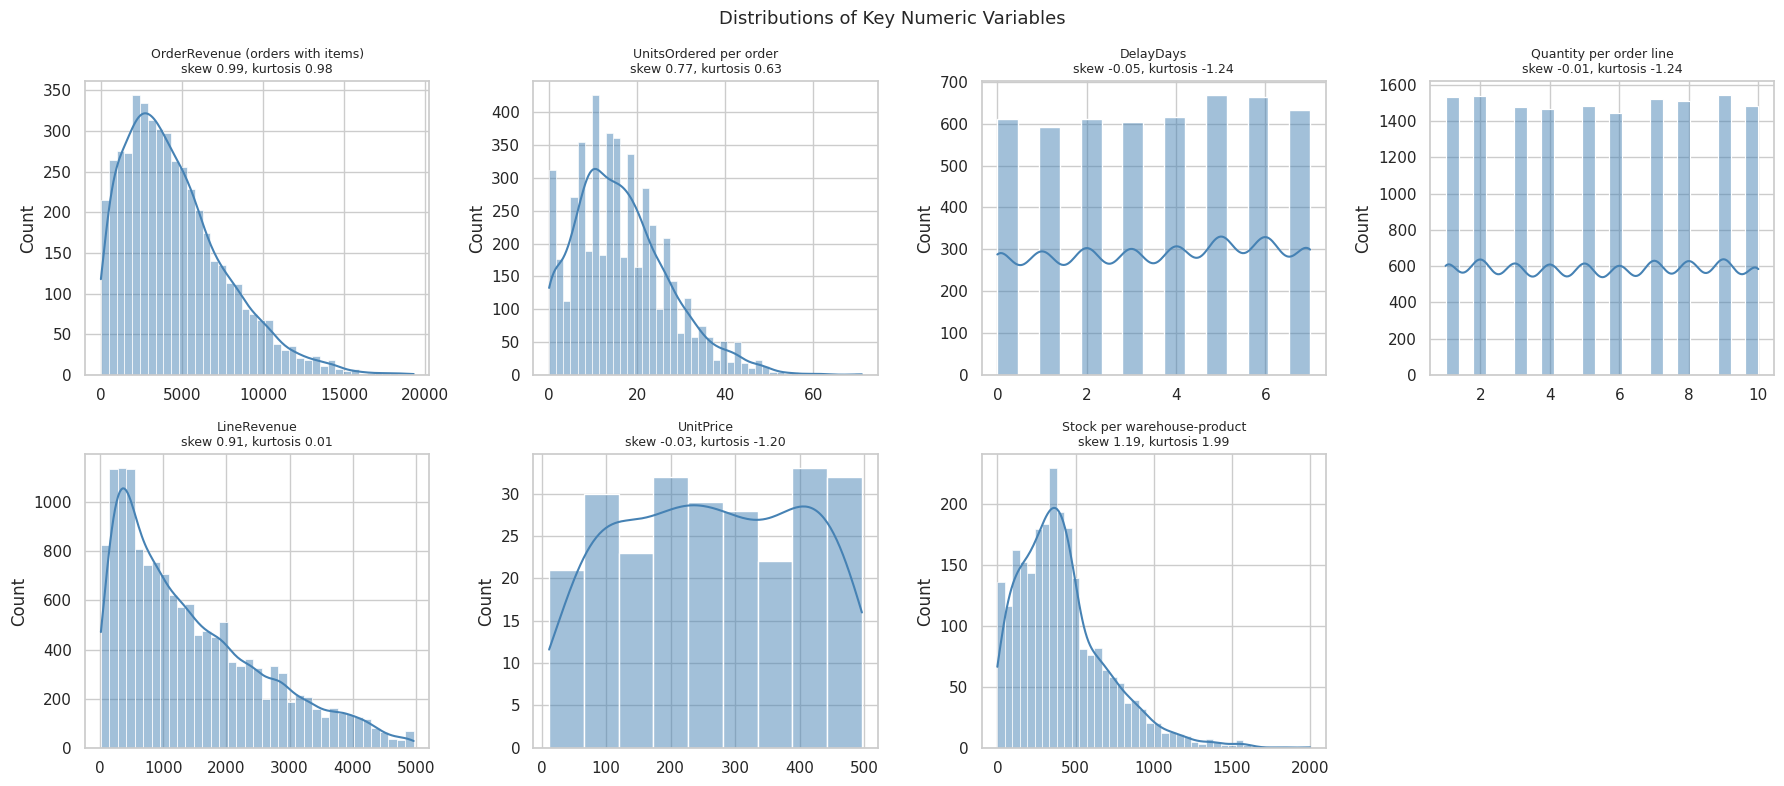


===== CORRELATION: Quantity, UnitPrice, LineRevenue =====
             Quantity  UnitPrice  LineRevenue
Quantity        1.000      0.005        0.662
UnitPrice       0.005      1.000        0.666
LineRevenue     0.662      0.666        1.000

----- TEST 1: Delay rate across warehouses (chi-square) -----
H0: Delay rate is the same in every warehouse
chi2 = 15.76, df = 14, p = 0.3280, Cramer's V = 0.056
Decision: FAIL TO REJECT H0 (no significant difference)

----- TEST 2: Delay days across warehouses (Kruskal-Wallis) -----
H0: Delay days have the same distribution in every warehouse
H = 10.04, p = 0.7594
Decision: FAIL TO REJECT H0 (no significant difference)

----- TEST 3: Delay rate across customer cities (chi-square) -----
H0: Delay rate is the same in every customer city
chi2 = 6.27, df = 3, p = 0.0993, Cramer's V = 0.035
Decision: FAIL TO REJECT H0 (no significant difference)

----- TEST 4: Return rate, delayed vs on-time orders (chi-square) -----
H0: Return rate is the same for d

,Route,Orders,DelayRate%,p_raw,p_bonferroni,Significant
7,Kano to Lagos,249,53.4,0.0007,0.0080,True
10,Lagos to Kano,701,66.8,0.0777,0.9327,False
4,Kano to Abuja,250,65.6,0.5708,1.0000,False
6,Kano to Kano,258,65.5,0.5854,1.0000,False
5,Kano to Ibadan,261,65.1,0.6731,1.0000,False
11,Lagos to Lagos,667,63.0,0.6963,1.0000,False
3,Abuja to Lagos,352,62.8,0.7480,1.0000,False
9,Lagos to Ibadan,644,63.2,0.8019,1.0000,False
0,Abuja to Abuja,320,64.4,0.8479,1.0000,False
8,Lagos to Abuja,635,63.9,0.9382,1.0000,False


In [85]:
from scipy import stats

if "cleaned" not in globals():
    cleaned = {os.path.basename(f).replace("_clean.csv", ""): pd.read_csv(f)
               for f in glob.glob(CLEAN + "*_clean.csv")}
order_master = pd.read_csv(CLEAN + "order_master.csv", parse_dates=["OrderDate"])
item_master = pd.read_csv(CLEAN + "item_master.csv", parse_dates=["OrderDate"])

# ================= DESCRIPTIVE STATISTICS =================
variables = {
    "OrderRevenue (orders with items)": order_master.loc[order_master["HasItems"] == 1, "OrderRevenue"],
    "UnitsOrdered per order": order_master["UnitsOrdered"],
    "DelayDays": order_master["DelayDays"],
    "Quantity per order line": item_master["Quantity"],
    "LineRevenue": item_master["LineRevenue"],
    "UnitPrice": cleaned["products"]["UnitPrice"],
    "Stock per warehouse-product": cleaned["inventory"]["Stock"],
}
descriptive = pd.DataFrame({
    name: {"mean": s.mean(), "median": s.median(), "mode": s.mode().iloc[0],
           "variance": s.var(), "std": s.std(), "skewness": s.skew(), "kurtosis": s.kurt()}
    for name, s in variables.items()}).T.round(2)
print("===== DESCRIPTIVE STATISTICS =====")
display(descriptive)
descriptive.to_csv(CLEAN + "descriptive_statistics.csv")

# Distributions
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (name, s) in zip(axes.flat, variables.items()):
    sns.histplot(s, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"{name}\nskew {s.skew():.2f}, kurtosis {s.kurt():.2f}", fontsize=9)
    ax.set_xlabel(""); ax.set_ylabel("Count")
axes.flat[-1].axis("off")
plt.suptitle("Distributions of Key Numeric Variables", fontsize=13)
plt.tight_layout()
plt.savefig(CHARTS + "25_distributions_grid.png", dpi=150, bbox_inches="tight")
plt.show()

# ================= CORRELATION (item level) =================
print("\n===== CORRELATION: Quantity, UnitPrice, LineRevenue =====")
print(item_master[["Quantity", "UnitPrice", "LineRevenue"]].corr().round(3).to_string())

# ================= HYPOTHESIS TESTS (alpha = 0.05) =================
ALPHA = 0.05

def chi_square(row_values, column_values, label, H0):
    table = pd.crosstab(row_values, column_values)
    chi2, p, dof, _ = stats.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    decision = "REJECT H0 (significant)" if p < ALPHA else "FAIL TO REJECT H0 (no significant difference)"
    print(f"\n----- {label} -----")
    print("H0:", H0)
    print(f"chi2 = {chi2:.2f}, df = {dof}, p = {p:.4f}, Cramer's V = {cramers_v:.3f}")
    print("Decision:", decision)
    return p

# Test 1: delay rate across the 15 warehouses
chi_square(order_master["WarehouseID"], order_master["IsDelayed"],
           "TEST 1: Delay rate across warehouses (chi-square)",
           "Delay rate is the same in every warehouse")

# Test 2: delay DAYS across warehouses (Kruskal-Wallis, no normality assumption)
groups = [g["DelayDays"].values for _, g in order_master.groupby("WarehouseID")]
h_stat, p_value = stats.kruskal(*groups)
print("\n----- TEST 2: Delay days across warehouses (Kruskal-Wallis) -----")
print("H0: Delay days have the same distribution in every warehouse")
print(f"H = {h_stat:.2f}, p = {p_value:.4f}")
print("Decision:", "REJECT H0 (significant)" if p_value < ALPHA else "FAIL TO REJECT H0 (no significant difference)")

# Test 3: delay rate across customer cities
chi_square(order_master["CustomerCity"], order_master["IsDelayed"],
           "TEST 3: Delay rate across customer cities (chi-square)",
           "Delay rate is the same in every customer city")

# Test 4: return rate, delayed vs on time
chi_square(order_master["IsDelayed"], order_master["HasReturn"],
           "TEST 4: Return rate, delayed vs on-time orders (chi-square)",
           "Return rate is the same for delayed and on-time orders")

# Test 5: return reason vs delivery outcome
returns_detail = cleaned["returns"].merge(order_master[["OrderID", "IsDelayed"]], on="OrderID")
chi_square(returns_detail["Reason"], returns_detail["IsDelayed"],
           "TEST 5: Return reason vs delivery outcome (chi-square)",
           "Return reason is independent of whether the shipment was delayed")

# Test 6: each warehouse-location x customer-city route vs all other routes (Bonferroni-corrected)
print("\n----- TEST 6: Each route vs all other routes (Bonferroni-corrected) -----")
print("H0: The route's delay rate equals the delay rate of all other routes")
route_rows = []
routes = order_master.groupby(["WarehouseLocation", "CustomerCity"])
for (warehouse_location, customer_city), group in routes:
    others = order_master.drop(group.index)
    table = [[group["IsDelayed"].sum(), len(group) - group["IsDelayed"].sum()],
             [others["IsDelayed"].sum(), len(others) - others["IsDelayed"].sum()]]
    chi2, p, _, _ = stats.chi2_contingency(table)
    route_rows.append((f"{warehouse_location} to {customer_city}", len(group),
                       round(group["IsDelayed"].mean() * 100, 1), p))
route_results = pd.DataFrame(route_rows, columns=["Route", "Orders", "DelayRate%", "p_raw"])
route_results["p_bonferroni"] = (route_results["p_raw"] * len(route_results)).clip(upper=1)
route_results["Significant"] = route_results["p_bonferroni"] < ALPHA
display(route_results.sort_values("p_raw").round(4))


## 4.1 Descriptive Statistics

| Variable | Mean | Median | Mode | Std dev | Variance | Skewness | Kurtosis |
|---|---|---|---|---|---|---|---|
| Order revenue (orders with items) | 4,548 | 3,949 | 366.5 | 3,149 | 9,915,637 | 0.99 | 0.98 |
| Units ordered per order | 16.49 | 15 | 10 | 10.77 | 116.1 | 0.77 | 0.63 |
| Delay days | 3.57 | 4 | 5 | 2.29 | 5.25 | -0.05 | -1.24 |
| Quantity per order line | 5.50 | 6 | 9 | 2.89 | 8.33 | -0.01 | -1.24 |
| Line revenue | 1,445 | 1,152 | 261.4 | 1,151 | 1,324,769 | 0.91 | 0.01 |
| Unit price | 264.2 | 263.6 | 11.78 | 140.0 | 19,601 | -0.03 | -1.20 |
| Stock per warehouse-product pair | 410.5 | 364 | 416 | 283.7 | 80,467 | 1.19 | 1.99 |

*Kurtosis is excess kurtosis (a normal distribution = 0). For continuous variables (order revenue, line revenue, unit price) the mode is just the single most repeated exact value and carries little meaning.*

**Interpretation**

1. **Money and stock are right-skewed.** Order revenue (skew 0.99), line revenue (0.91) and stock (1.19) have means above medians (4,548 vs 3,949 for orders). A minority of large orders and large stock holdings pull the average up, so the **median is the fairer "typical" value** for these variables. Stock also has the heaviest tails (kurtosis 1.99), meaning more extreme values than a normal distribution, which matches the 87 high-stock outliers found earlier.
2. **Delay days, quantity and unit price are flat, not bell-shaped.** All three have skewness near zero and kurtosis near -1.2, which is the signature of a **uniform distribution**: every value from 0 to 7 days, 1 to 10 units, or 12 to 497 in price is about equally likely. Real operations rarely look like this, which supports the earlier observation that the data is probably simulated.
3. **Variability is high relative to the mean for revenue** (standard deviation 3,149 vs mean 4,548, about 69%), so order values are quite unpredictable. Delay is similarly spread: a standard deviation of 2.29 days around a 3.57-day mean.

**Business implication:** Use medians when reporting typical order value or stock. Because delay is spread evenly across 0 to 7 days, there is no "usual" delay to aim at, and averages hide the full spread. For future modelling, revenue and stock would benefit from a log transform to reduce skew.

## 4.2 Distribution and Correlation Analysis

**Chart 25** (distributions grid, saved as `25_distributions_grid.png`) shows each variable's histogram with its skewness and kurtosis.

**Interpretation:** Revenue, units and stock have a long right tail, while delay days, quantity and unit price are flat across their range. No variable is approximately normal.

**Business implication:** Because the key operational measures are not normally distributed, tests that assume normality (such as ANOVA) were avoided. A Kruskal-Wallis test was used for delay days, and chi-square tests for proportions.

**Correlation at order-line level**

| | Quantity | Unit price | Line revenue |
|---|---|---|---|
| Quantity | 1.00 | 0.005 | 0.66 |
| Unit price | 0.005 | 1.00 | 0.67 |
| Line revenue | 0.66 | 0.67 | 1.00 |

**Interpretation:** Quantity and unit price are unrelated to each other (0.005), and each drives line revenue about equally (0.66 and 0.67). That is expected, since line revenue is quantity multiplied by price.

**Business implication:** Customers do not buy more of cheaper items, so volume and price contribute independently. Revenue grows by raising the units per order or the value of items sold, and each lever is worth about the same. This is consistent with the earlier finding that revenue at order level is driven by basket size (units ordered r = 0.89), because larger baskets add more lines.

## 4.3 Hypothesis Tests

All tests use a significance level of 0.05. Chi-square tests are used for rates (proportions), and Kruskal-Wallis for delay days because they are not normally distributed. Cramér's V measures effect size (0 = no relationship, 1 = perfect; below 0.1 is negligible).

| # | Question | Test | Statistic | p-value | Cramér's V | Decision |
|---|---|---|---|---|---|---|
| 1 | Does the delay rate differ across the 15 warehouses? | Chi-square | 15.76 (df 14) | 0.328 | 0.056 | No significant difference |
| 2 | Do delay days differ across warehouses? | Kruskal-Wallis | H = 10.04 | 0.759 | n/a | No significant difference |
| 3 | Does the delay rate differ across customer cities? | Chi-square | 6.27 (df 3) | 0.099 | 0.035 | No significant difference |
| 4 | Do delayed orders have a different return rate? | Chi-square | 0.01 (df 1) | 0.928 | 0.001 | No significant difference |
| 5 | Is return reason related to delivery outcome? | Chi-square | 3.23 (df 2) | 0.199 | 0.080 | No significant difference |
| 6 | Does any single route differ from the rest? | Chi-square per route, Bonferroni-corrected (12 comparisons) | see below | see below | n/a | **Kano to Lagos is significant** |

### Test 1: Delay rate across warehouses
**H0:** the delay rate is the same in all warehouses. **H1:** at least one warehouse differs.
**Result:** p = 0.328, so H0 is not rejected. The apparent range of 58.7% (W01) to 68.0% (W05) is within what chance produces with about 330 shipments per warehouse.
**Business meaning:** No warehouse is a proven under-performer or over-performer on delay rate. Delay is a company-wide issue, so fixes should target shared processes, not individual warehouses.

### Test 2: Delay days across warehouses
**H0:** delay days are distributed the same in every warehouse. **H1:** at least one differs.
**Result:** H = 10.04, p = 0.759, so H0 is not rejected.
**Business meaning:** Delay severity (not just the delay rate) is also the same everywhere. Test 1 and Test 2 agree, which strengthens the conclusion that warehouses perform alike.

### Test 3: Delay rate across customer cities
**H0:** the delay rate is the same in every customer city. **H1:** at least one city differs.
**Result:** p = 0.099, so H0 is not rejected, though the result is close to the 0.05 line. The effect is negligible (V = 0.035).
**Business meaning:** Delivery to Kano (65.7%) and Lagos (61.0%) do not differ reliably. As the route test shows, Lagos's lower rate is driven by a single route and not by the city overall.

### Test 4: Return rate, delayed vs on-time orders
**H0:** the return rate is the same for delayed and on-time orders. **H1:** it differs.
**Result:** p = 0.928, which is effectively no difference (9.42% vs 9.54%).
**Business meaning:** Reducing delays should not be expected to reduce returns. Returns need to be addressed through order accuracy and handling.

### Test 5: Return reason vs delivery outcome
**H0:** return reason is independent of whether the shipment was delayed. **H1:** they are related.
**Result:** p = 0.199, so H0 is not rejected. "Late Delivery" returns (64.3% from delayed shipments) are no more likely to come from delayed shipments than "Wrong Item" (67.5%) or "Damaged" (57.9%) returns.
**Business meaning:** The recorded return reason does not match what happened in delivery, so return reasons are unreliable for diagnosing delivery problems. Recording the promised delivery date and validating the reason field would fix this.

### Test 6: Delay rate by route (12 routes, Bonferroni-corrected)
**H0:** a route's delay rate equals the delay rate of all other routes. **H1:** it differs.
Testing 12 routes at once raises the chance of a false positive, so p-values were multiplied by 12 (Bonferroni correction).

| Route | Orders | Delay rate | Raw p | Adjusted p | Significant |
|---|---|---|---|---|---|
| **Kano to Lagos** | 249 | **53.4%** | 0.0007 | **0.008** | **Yes** |
| Lagos to Kano | 701 | 66.8% | 0.078 | 0.933 | No |
| All other 10 routes | 250 to 667 | 62.8% to 65.6% | 0.57 to 0.996 | 1.000 | No |

**Result:** Only **Kano to Lagos** differs from the rest, and the difference survives the correction (adjusted p = 0.008). Its delay rate is about 10 points below the company average of 63.7%.
**Business meaning:** This is the one route doing something different, and the only positive finding in the delivery data. Whatever is working there (carrier, dispatch process, loading) should be identified and tried on other routes. It should be treated as a lead to investigate and not a proven cause, since the data holds no operational detail to explain it.

## 4.4 Summary of Statistical Findings

1. **Five of six tests found no significant difference.** Delay rate and delay days do not differ across warehouses or (significantly) across cities, and returns do not differ by delay outcome.
2. **Delay is a system-wide problem.** With about 64% of shipments delayed everywhere, improvement should come from shared processes and not from individual warehouses.
3. **Kano to Lagos is the one exceptional route** (53.4% delayed, adjusted p = 0.008) and the best lead for improvement.
4. **Return reasons do not reflect delivery outcomes** and should be validated.
5. **Revenue and stock are right-skewed**, so medians are used for "typical" values. Delay, quantity and price are uniformly spread, which suggests the data may be simulated.

===== FEATURE DATASET ===== (5000, 43) | missing values: 1765


,OrderFrequency,AvgCustomerSpend,CLV_Estimate,ReturnFrequency,DeliveryEfficiencyScore,WarehouseUtilisationIndex,InventoryTurnover,SeasonalDemandIndex
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,6.10,4246.22,25732.57,0.09,42.64,86.70,0.04,1.00
std,2.33,1866.25,15082.98,0.13,1.95,6.38,0.00,0.04
min,1.00,0.00,0.00,0.00,38.96,72.94,0.03,0.96
25%,4.00,3082.01,14784.34,0.00,41.33,81.54,0.03,0.97
50%,6.00,4199.86,24084.23,0.00,43.22,86.65,0.04,0.97
75%,8.00,5283.45,34465.34,0.17,43.64,90.15,0.04,1.06
max,15.00,13076.80,85709.97,1.00,45.91,100.00,0.04,1.07



===== WAREHOUSE FEATURES =====


,WarehouseID,Shipments,WarehouseDelayRate,WarehouseAvgDelayDays,Employees,TotalStock,UniqueProducts,UnitsSold,WarehouseOnTimeRate,DeliveryEfficiencyScore,ShipmentsPerEmployee,WarehouseUtilisationIndex,InventoryTurnover
0,W01,332,0.59,3.46,15,56539,154,2148.0,41.27,45.91,22.13,72.94,0.04
1,W02,322,0.64,3.44,12,73012,169,2500.0,36.02,43.46,26.83,94.19,0.03
2,W03,344,0.67,3.68,17,66559,170,2502.0,32.56,39.99,20.24,85.86,0.04
3,W04,354,0.63,3.52,15,69696,167,2646.0,36.72,43.22,23.60,89.91,0.04
4,W05,334,0.68,3.79,14,63125,163,2019.0,32.04,38.96,23.86,81.43,0.03
5,W06,319,0.66,3.61,14,69177,164,2180.0,34.17,41.33,22.79,89.24,0.03
6,W07,371,0.60,3.47,17,68338,170,3065.0,39.62,45.01,21.82,88.16,0.04
7,W08,332,0.64,3.67,13,66971,159,2177.0,36.14,41.89,25.54,86.40,0.03
8,W09,332,0.67,3.68,14,63604,157,2477.0,32.53,39.97,23.71,82.05,0.04
9,W10,334,0.60,3.49,15,67169,157,2168.0,40.12,45.17,22.27,86.65,0.03



===== MONTHLY DEMAND =====


,Orders,DaysObserved,OrdersPerDay,SeasonalDemandIndex,PeakMonthFlag,DemandTrendPct,DemandTrend3M
OrderYearMonth,,,,,,,
2026-01,594,31,19.16,0.96,0,NaN,NaN
2026-02,577,28,20.61,1.04,0,7.55,NaN
2026-03,597,31,19.26,0.97,0,-6.55,19.68
2026-04,638,30,21.27,1.07,1,10.43,20.38
2026-05,612,31,19.74,0.99,0,-7.17,20.09
2026-06,579,30,19.30,0.97,0,-2.24,20.10
2026-07,595,31,19.19,0.97,0,-0.55,19.41
2026-08,654,31,21.10,1.06,1,9.92,19.86
2026-09,154,8,19.25,0.97,0,-8.75,19.85



===== CUSTOMER SEGMENTATION: silhouette by k =====
{2: np.float64(0.284), 3: np.float64(0.308), 4: np.float64(0.308), 5: np.float64(0.287)}

Chosen k = 3. Segment profile (S1 = highest value):


,Customers,AvgOrders,AvgSpend,AvgNetRevenue,TotalNetRevenue,AvgReturnFreq,AvgRecencyDays,PctCustomers,PctNetRevenue
Segment,,,,,,,,,
S1,351,7.06,5276.96,24350.44,8547003.86,0.07,34.01,35.42,59.19
S2,215,4.64,3743.42,11875.18,2553163.90,0.31,47.89,21.70,17.68
S3,425,3.59,3414.92,7856.59,3339050.46,0.00,61.46,42.89,23.12


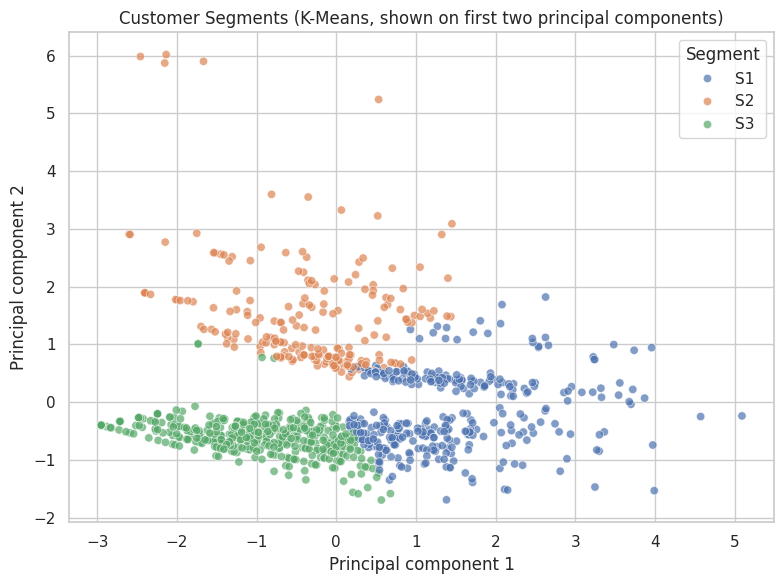

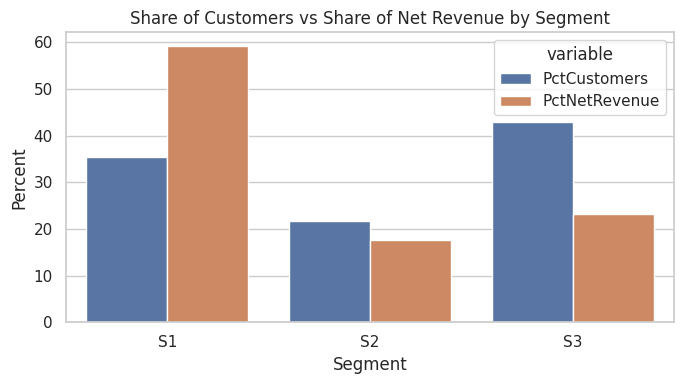


===== WAREHOUSE SEGMENTS =====


,Warehouses,AvgDelayRate,AvgShipmentsPerEmployee,AvgStock,AvgTurnover
Cluster,,,,,
0,"W02, W03, W04, W05, W06, W08, W09, W10, W11, W13",0.648,23.767,67396.300,0.034
1,"W01, W07",0.596,21.978,62438.500,0.041
2,"W12, W14, W15",0.631,35.559,69641.333,0.039


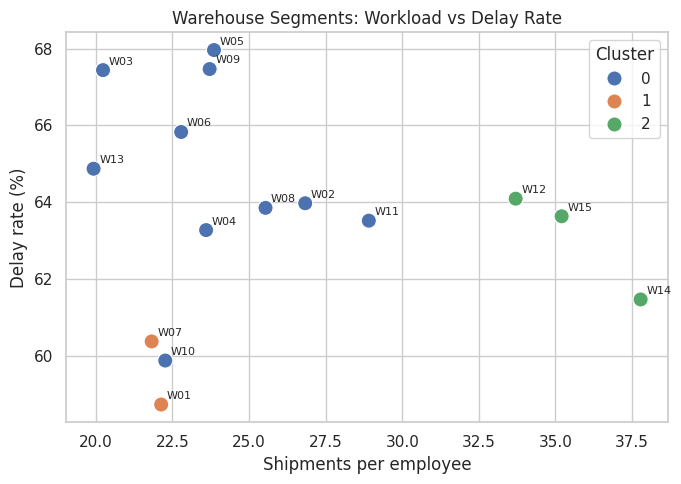


Saved Feature_Engineered_Dataset.csv and supporting files


In [86]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# ---------- 0. Reload if the session restarted ----------
if "cleaned" not in globals():
    cleaned = {os.path.basename(f).replace("_clean.csv", ""): pd.read_csv(f)
               for f in glob.glob(CLEAN + "*_clean.csv")}
order_master = pd.read_csv(CLEAN + "order_master.csv", parse_dates=["OrderDate"])
item_master = pd.read_csv(CLEAN + "item_master.csv", parse_dates=["OrderDate"])
inventory = cleaned["inventory"]
employees = cleaned["employees"]

net_orders = order_master[order_master["CountsAsNetRevenue"] == 1]
net_items = item_master[item_master["CountsAsNetRevenue"] == 1]
observation_months = (order_master["OrderDate"].max() - order_master["OrderDate"].min()).days / 30.44

# ================= CUSTOMER FEATURES =================
customers_f = (order_master.groupby("CustomerID")
               .agg(OrderFrequency=("OrderID", "count"), ReturnOrders=("HasReturn", "sum"),
                    LastOrder=("OrderDate", "max")).reset_index())
net_by_customer = (net_orders.groupby("CustomerID")
                   .agg(NetOrders=("OrderID", "count"), NetRevenue=("OrderRevenue", "sum")).reset_index())
customers_f = customers_f.merge(net_by_customer, on="CustomerID", how="left")
customers_f[["NetOrders", "NetRevenue"]] = customers_f[["NetOrders", "NetRevenue"]].fillna(0)
customers_f["AvgCustomerSpend"] = np.where(customers_f["NetOrders"] > 0,
                                           customers_f["NetRevenue"] / customers_f["NetOrders"].replace(0, np.nan), 0)
customers_f["CLV_Estimate"] = customers_f["NetRevenue"] / observation_months * 12   # annualised net revenue
customers_f["ReturnFrequency"] = customers_f["ReturnOrders"] / customers_f["OrderFrequency"]
customers_f["RecencyDays"] = (order_master["OrderDate"].max() - customers_f["LastOrder"]).dt.days

# ================= INVENTORY TURNOVER (warehouse-product level) =================
units_sold = (net_items.groupby(["WarehouseID", "ProductID"])["Quantity"].sum()
              .rename("UnitsSold").reset_index())
turnover = inventory.merge(units_sold, on=["WarehouseID", "ProductID"], how="left")
turnover["UnitsSold"] = turnover["UnitsSold"].fillna(0)
turnover["InventoryTurnover"] = turnover["UnitsSold"] / turnover["Stock"].replace(0, np.nan)

# ================= WAREHOUSE FEATURES =================
warehouse_features = (order_master.groupby("WarehouseID")
    .agg(Shipments=("OrderID", "count"), WarehouseDelayRate=("IsDelayed", "mean"),
         WarehouseAvgDelayDays=("DelayDays", "mean"))
    .join(employees.groupby("WarehouseID").size().rename("Employees"))
    .join(inventory.groupby("WarehouseID").agg(TotalStock=("Stock", "sum"), UniqueProducts=("ProductID", "nunique")))
    .join(turnover.groupby("WarehouseID")["UnitsSold"].sum())
    .reset_index())
warehouse_features["WarehouseOnTimeRate"] = (1 - warehouse_features["WarehouseDelayRate"]) * 100
warehouse_features["DeliveryEfficiencyScore"] = (0.5 * (1 - warehouse_features["WarehouseDelayRate"])
        + 0.5 * (1 - warehouse_features["WarehouseAvgDelayDays"] / 7)) * 100
warehouse_features["ShipmentsPerEmployee"] = warehouse_features["Shipments"] / warehouse_features["Employees"]
warehouse_features["WarehouseUtilisationIndex"] = warehouse_features["TotalStock"] / warehouse_features["TotalStock"].max() * 100
warehouse_features["InventoryTurnover"] = warehouse_features["UnitsSold"] / warehouse_features["TotalStock"]

# ================= SEASONAL DEMAND AND TREND (monthly) =================
monthly = order_master.groupby("OrderYearMonth").agg(Orders=("OrderID", "count"))
days_observed = list(pd.PeriodIndex(monthly.index, freq="M").days_in_month)
days_observed[-1] = int(order_master["OrderDate"].max().day)      # September is partial
monthly["DaysObserved"] = days_observed
monthly["OrdersPerDay"] = monthly["Orders"] / monthly["DaysObserved"]
monthly["SeasonalDemandIndex"] = monthly["OrdersPerDay"] / monthly["OrdersPerDay"].mean()
monthly["PeakMonthFlag"] = (monthly["SeasonalDemandIndex"] >= 1.05).astype(int)
monthly["DemandTrendPct"] = monthly["OrdersPerDay"].pct_change() * 100
monthly["DemandTrend3M"] = monthly["OrdersPerDay"].rolling(3).mean()

# ================= FINAL FEATURE-ENGINEERED DATASET (one row per order) =================
features = (order_master
    .merge(customers_f[["CustomerID", "OrderFrequency", "AvgCustomerSpend", "CLV_Estimate",
                        "ReturnFrequency", "RecencyDays"]], on="CustomerID", how="left")
    .merge(warehouse_features[["WarehouseID", "WarehouseOnTimeRate", "DeliveryEfficiencyScore",
                               "ShipmentsPerEmployee", "WarehouseUtilisationIndex", "InventoryTurnover"]],
           on="WarehouseID", how="left")
    .merge(monthly[["SeasonalDemandIndex", "PeakMonthFlag", "DemandTrendPct", "DemandTrend3M"]].reset_index(),
           on="OrderYearMonth", how="left"))
features["DeliveryDuration"] = features["DelayDays"]     # proxy: no ship/delivery dates exist
print("===== FEATURE DATASET =====", features.shape, "| missing values:", int(features.isna().sum().sum()))
display(features[["OrderFrequency", "AvgCustomerSpend", "CLV_Estimate", "ReturnFrequency",
                  "DeliveryEfficiencyScore", "WarehouseUtilisationIndex", "InventoryTurnover",
                  "SeasonalDemandIndex"]].describe().round(2))
print("\n===== WAREHOUSE FEATURES =====")
display(warehouse_features.round(2))
print("\n===== MONTHLY DEMAND =====")
display(monthly.round(2))

# ================= SEGMENTATION 1: CUSTOMERS (K-Means) =================
segment_inputs = ["OrderFrequency", "AvgCustomerSpend", "NetRevenue", "ReturnFrequency"]
scaled = StandardScaler().fit_transform(customers_f[segment_inputs])
silhouette = {k: silhouette_score(scaled, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(scaled))
              for k in range(2, 6)}
print("\n===== CUSTOMER SEGMENTATION: silhouette by k =====")
print({k: round(v, 3) for k, v in silhouette.items()})
best_k = max(range(3, 6), key=lambda k: silhouette[k])           # at least 3 segments for usefulness
customers_f["Cluster"] = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit_predict(scaled)
rank = customers_f.groupby("Cluster")["NetRevenue"].mean().sort_values(ascending=False).index
customers_f["Segment"] = customers_f["Cluster"].map({c: f"S{i + 1}" for i, c in enumerate(rank)})

profile = (customers_f.groupby("Segment")
           .agg(Customers=("CustomerID", "count"), AvgOrders=("OrderFrequency", "mean"),
                AvgSpend=("AvgCustomerSpend", "mean"), AvgNetRevenue=("NetRevenue", "mean"),
                TotalNetRevenue=("NetRevenue", "sum"), AvgReturnFreq=("ReturnFrequency", "mean"),
                AvgRecencyDays=("RecencyDays", "mean")))
profile["PctCustomers"] = profile["Customers"] / profile["Customers"].sum() * 100
profile["PctNetRevenue"] = profile["TotalNetRevenue"] / profile["TotalNetRevenue"].sum() * 100
print(f"\nChosen k = {best_k}. Segment profile (S1 = highest value):")
display(profile.round(2))

coords = PCA(n_components=2, random_state=42).fit_transform(scaled)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=customers_f["Segment"].sort_values().values
                if False else customers_f["Segment"], hue_order=sorted(customers_f["Segment"].unique()),
                palette="deep", alpha=0.7)
plt.title("Customer Segments (K-Means, shown on first two principal components)")
plt.xlabel("Principal component 1"); plt.ylabel("Principal component 2")
plt.tight_layout(); plt.savefig(CHARTS + "26_customer_segments_pca.png", dpi=150, bbox_inches="tight"); plt.show()

plt.figure(figsize=(7, 4))
share = profile[["PctCustomers", "PctNetRevenue"]].reset_index().melt(id_vars="Segment")
sns.barplot(data=share, x="Segment", y="value", hue="variable")
plt.title("Share of Customers vs Share of Net Revenue by Segment")
plt.xlabel("Segment"); plt.ylabel("Percent")
plt.tight_layout(); plt.savefig(CHARTS + "27_segment_customer_vs_revenue_share.png", dpi=150, bbox_inches="tight"); plt.show()

# ================= SEGMENTATION 2: WAREHOUSES (K-Means, k = 3) =================
warehouse_inputs = ["WarehouseDelayRate", "ShipmentsPerEmployee", "TotalStock", "InventoryTurnover"]
warehouse_scaled = StandardScaler().fit_transform(warehouse_features[warehouse_inputs])
warehouse_features["Cluster"] = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(warehouse_scaled)
print("\n===== WAREHOUSE SEGMENTS =====")
display(warehouse_features.groupby("Cluster")
        .agg(Warehouses=("WarehouseID", lambda s: ", ".join(s)), AvgDelayRate=("WarehouseDelayRate", "mean"),
             AvgShipmentsPerEmployee=("ShipmentsPerEmployee", "mean"), AvgStock=("TotalStock", "mean"),
             AvgTurnover=("InventoryTurnover", "mean")).round(3))
plt.figure(figsize=(7, 5))
sns.scatterplot(data=warehouse_features, x="ShipmentsPerEmployee", y=warehouse_features["WarehouseDelayRate"] * 100,
                hue="Cluster", palette="deep", s=120)
for _, row in warehouse_features.iterrows():
    plt.annotate(row["WarehouseID"], (row["ShipmentsPerEmployee"], row["WarehouseDelayRate"] * 100),
                 xytext=(4, 4), textcoords="offset points", fontsize=8)
plt.title("Warehouse Segments: Workload vs Delay Rate")
plt.xlabel("Shipments per employee"); plt.ylabel("Delay rate (%)")
plt.tight_layout(); plt.savefig(CHARTS + "28_warehouse_segments.png", dpi=150, bbox_inches="tight"); plt.show()

# ================= SAVE =================
features.to_csv(root + "/Data/Feature_Engineered_Dataset.csv", index=False)
customers_f.to_csv(CLEAN + "customer_features_segments.csv", index=False)
warehouse_features.to_csv(CLEAN + "warehouse_features.csv", index=False)
monthly.to_csv(CLEAN + "monthly_demand_features.csv")
print("\nSaved Feature_Engineered_Dataset.csv and supporting files")

# 5. Feature Engineering

| Feature | How it was built | Why created | Business value | How it helps ML |
|---|---|---|---|---|
| DeliveryDuration | Copy of `DelayDays` (no ship or delivery dates exist, so delay days is the only time measure) | Measure how late each delivery was | Shows how long customers wait beyond schedule | Regression target for delay length; input for return or satisfaction models |
| IsDelayed (delay flag) | 1 if `DelayDays` >= 3 (inferred rule, matches supplied Status on all 5,000 rows) | Turn delay into a yes/no outcome | Gives a single on-time KPI | Classification target for delay prediction |
| AvgCustomerSpend | Net revenue ÷ net orders per customer | Capture typical basket value | Identifies high-value buyers | Predictor for customer value and churn models |
| OrderFrequency | Number of orders per customer | Capture buying habit | Separates loyal from occasional buyers | Strong predictor of future orders and CLV |
| CLV_Estimate | Net revenue ÷ months observed x 12 (annualised; ignores margin and churn) | Estimate what a customer is worth per year | Prioritises retention spending | Regression target or input for customer-value models |
| ReturnFrequency | Orders with a return ÷ orders per customer | Capture return behaviour | Flags customers or patterns costing money | Predictor in return-prediction models |
| InventoryTurnover | Units sold ÷ stock held, per warehouse | Show how fast stock moves | Highlights overstocked or slow warehouses | Input for demand forecasting and replenishment |
| WarehouseUtilisationIndex | Stock held ÷ highest warehouse stock x 100 (proxy, since capacity was not provided) | Estimate how full each warehouse is relative to the largest | Guides stock rebalancing | Input for warehouse performance models |
| WarehouseOnTimeRate | On-time share of a warehouse's shipments (stand-in for supplier reliability, which cannot be built because suppliers link to no table) | Measure dependability | Ranks warehouses for review | Input for reliability and delay models |
| DeliveryEfficiencyScore | Half on-time rate, half (1 − average delay ÷ 7), scaled 0 to 100 | Combine frequency and severity of delay | One comparable score per warehouse | Compact input; target for warehouse performance |
| SeasonalDemandIndex / PeakMonthFlag | Orders per day in a month ÷ average orders per day (September adjusted for 8 days); peak if >= 1.05 | Show which months run hot | Supports staffing and stock planning | Captures seasonality in demand forecasting |
| DemandTrendPct / DemandTrend3M | Month-on-month change and 3-month rolling average of orders per day | Show direction of demand | Early warning of growth or decline | Trend input for forecasting |

**Caution for modelling:** customer and warehouse features are calculated over all orders, including the order being predicted, which leaks information into a model. Before training, they should be rebuilt using only data from before each order. Features also rest on one 8-month window with an incomplete inventory table, so they are indicative.

Final dataset: `Data/Feature_Engineered_Dataset.csv`, one row per order, with the original merged fields plus the engineered features above.

## 5.1 Feature Engineering Results

Final dataset: `Data/Feature_Engineered_Dataset.csv`, 5,000 rows (one per order) x 43 columns.

**The 1,765 missing values are expected.** They come only from the trend features: `DemandTrendPct` is blank for January (594 orders, no prior month) and `DemandTrend3M` is blank for January and February (594 + 577 orders, a 3-month window needs three months). 594 + 1,171 = 1,765. They were left blank on purpose, since filling them would invent data. Models can drop those two columns or those months.

**Order-level summary of key features** (customer features repeat on each of a customer's orders, so frequent buyers weigh more: mean 6.10 orders vs 5.05 at customer level)

| Feature | Mean | Range |
|---|---|---|
| OrderFrequency | 6.10 | 1 to 15 |
| AvgCustomerSpend | 4,246 | 0 to 13,077 |
| CLV_Estimate (annualised) | 25,733 | 0 to 85,710 |
| ReturnFrequency | 0.09 | 0 to 1.00 |
| DeliveryEfficiencyScore | 42.6 | 39.0 to 45.9 |
| WarehouseUtilisationIndex | 86.7 | 72.9 to 100 |
| InventoryTurnover | 0.04 | 0.03 to 0.04 |
| SeasonalDemandIndex | 1.00 | 0.96 to 1.07 |

**Warehouse findings**

- **Delivery efficiency scores are tightly bunched** (39.0 to 45.9). The best are W01 (45.9), W10 (45.2) and W07 (45.0), and the weakest are W05 (39.0), W09 (40.0) and W03 (40.0). This agrees with Test 1: warehouse differences are small and not statistically significant.
- **Utilisation proxy** (stock held vs the largest warehouse): W12 is 100 (77,517 units) and W01 is lowest at 72.9 (56,539 units). This is an estimate, since capacity was not provided.
- **Inventory turnover is very low.** The warehouses hold about 1.0 million units against about 36,400 units sold in 8 months (net orders), roughly **28 times** what was sold, a turnover of about 0.04. This is understated, because only shipped pairs that have an inventory record are counted (about two thirds of them). Even adjusting for that, turnover would be about 0.055. Either SwiftLog is heavily overstocked, or the inventory table does not reflect true on-hand stock. Treat it as indicative.
- **Workload:** W14 (37.8), W15 (35.2) and W12 (33.7) handle the most shipments per employee, against about 20 to 25 at most others.

**Demand features** (orders per day, so February's 28 days and September's 8 days are comparable)

| Month | Orders per day | Seasonal index | Peak flag |
|---|---|---|---|
| Apr | 21.27 | 1.07 | Yes |
| Aug | 21.10 | 1.06 | Yes |
| Feb | 20.61 | 1.04 | No |
| All other months | 19.2 to 19.7 | 0.96 to 0.99 | No |

Seasonality is weak (every month is within about 7% of average) and the 3-month trend is flat (19.4 to 20.4 orders per day). Per day, February is among the stronger months, which refines chart 03, where it looked lowest on raw order count only because it has fewer days.

**Business implication:** Demand planning can assume stable volume, with modest peaks in April and August. The inventory features point to a stock problem (overstock or unreliable records) more than a delivery problem. The delivery-related features show little spread between warehouses, which will limit how well delay can be predicted from them.

# 6. Segmentation and Pattern Discovery

## 6.1 Customer segmentation (K-Means)

**Method:** K-Means on four standardised features (order frequency, average spend, net revenue, return frequency) for the 991 customers who ordered. Silhouette scores were 0.284 (k=2), 0.308 (k=3), 0.308 (k=4) and 0.287 (k=5). k=3 was chosen (tied with 4, but simpler to act on). Segments are ranked by average net revenue, S1 highest. Charts: `26_customer_segments_pca.png` and `27_segment_customer_vs_revenue_share.png`.

| Segment | Customers | % of customers | Avg orders | Avg spend per order | Net revenue per customer | % of net revenue | Return freq. | Days since last order |
|---|---|---|---|---|---|---|---|---|
| **S1: Loyal high-value** | 351 | 35.4% | 7.06 | 5,277 | 24,350 | **59.2%** | 0.07 | 34 |
| **S2: Return-prone mid-value** | 215 | 21.7% | 4.64 | 3,743 | 11,875 | 17.7% | **0.31** | 48 |
| **S3: Low-frequency, low-value** | 425 | 42.9% | 3.59 | 3,415 | 7,857 | 23.1% | 0.00 | **61** |

**Interpretation:**
1. **S1 is the core of the business:** 35% of customers produce 59% of net revenue, about 3.1x the revenue of an S3 customer, buying twice as often at higher order values, with few returns, and ordering most recently.
2. **S2 buys moderately but returns heavily:** about 0.31 returns per order, more than four times S1's rate.
3. **S3 is the largest group and the weakest:** it has the fewest orders, lowest value, no returns, and has gone longest since its last order (61 days), so it is the most likely to be lapsing.
4. **Caution:** the silhouette score of 0.31 shows moderate overlap, so use the segments for targeting and not as hard boundaries. S2 and S3 are separated mainly by return behaviour, which the earlier tests found to be close to random in this data, so those two should not be over-interpreted.

**Business use:**
- **S1:** priority service and loyalty rewards, and protect these customers from delays and cancellations.
- **S2:** investigate order accuracy and product quality on their orders, and follow up after returns.
- **S3:** win-back campaigns and bundles to increase basket size (units per order is the main driver of order value, r = 0.89).

## 6.2 Warehouse segmentation (K-Means, k = 3)

Inputs: delay rate, shipments per employee, total stock, inventory turnover. Chart: `28_warehouse_segments.png`. With only 15 warehouses this is exploratory.

| Segment | Warehouses | Delay rate | Shipments per employee | Avg stock | Turnover |
|---|---|---|---|---|---|
| Lowest delay | W01, W07 | 59.6% | 22.0 | 62,439 | 0.041 |
| Typical (10 warehouses) | W02, W03, W04, W05, W06, W08, W09, W10, W11, W13 | 64.8% | 23.8 | 67,396 | 0.034 |
| High workload per employee | W12, W14, W15 | 63.1% | 35.6 | 69,641 | 0.039 |

**Interpretation:**
1. **W01 and W07** have the lowest delay rate and the best turnover. They were grouped after the fact, and Test 1 found warehouse differences overall are not significant, so they are a watch-list for good practice and not a proven result.
2. **W12, W14 and W15** carry about 50% more shipments per employee than the typical group (35.6 vs 23.8) with a similar delay rate (63.1% vs 64.8%).

**Business implication:** Heavier workload per employee does not show up as more delay, so the typical group may be over-staffed relative to W12, W14 and W15, or those three are running efficiently. A monitored staffing pilot would settle this. Supplier and regional segmentation were not possible: suppliers link to no other table, and regional differences are not significant.

In [87]:
products = cleaned["products"]
net_lines = item_master[item_master["CountsAsNetRevenue"] == 1]
product_summary = (net_lines.groupby(["ProductID"], as_index=False)
                   .agg(NetRevenue=("LineRevenue", "sum"), Units=("Quantity", "sum"))
                   .merge(products[["ProductID", "Category"]], on="ProductID"))
print("===== TOP 10 PRODUCTS BY NET REVENUE =====")
display(product_summary.nlargest(10, "NetRevenue").round(0))
print(f"Top 10 products = {product_summary.nlargest(10, 'NetRevenue')['NetRevenue'].sum() / product_summary['NetRevenue'].sum() * 100:.1f}% of net revenue")

lines = item_master.groupby("ProductID").size().rename("Lines")
returned_lines = item_master[item_master["HasReturn"] == 1].groupby("ProductID").size().rename("LinesInReturnedOrders")
return_table = pd.concat([lines, returned_lines], axis=1).fillna(0).reset_index()
return_table["ReturnIncidence%"] = return_table["LinesInReturnedOrders"] / return_table["Lines"] * 100
print("\n===== TOP 10 PRODUCTS BY RETURN INCIDENCE (order-level attribution, indicative) =====")
display(return_table.merge(products[["ProductID", "Category"]], on="ProductID").nlargest(10, "ReturnIncidence%").round(1))

===== TOP 10 PRODUCTS BY NET REVENUE =====


,ProductID,NetRevenue,Units,Category
84,P085,143028.0,290,Food
39,P040,131276.0,277,Electronics
24,P025,123456.0,266,Food
158,P159,120645.0,252,Fashion
185,P186,119982.0,260,Fashion
228,P229,119882.0,242,Food
208,P209,116844.0,244,Fashion
219,P220,114378.0,252,Food
155,P156,113149.0,272,Food
25,P026,112535.0,267,Fashion


Top 10 products = 8.4% of net revenue

===== TOP 10 PRODUCTS BY RETURN INCIDENCE (order-level attribution, indicative) =====


,ProductID,Lines,LinesInReturnedOrders,ReturnIncidence%,Category
31,P032,47,10,21.3,Fashion
16,P017,53,10,18.9,Fashion
107,P108,60,11,18.3,Electronics
19,P020,59,10,16.9,Food
176,P177,66,11,16.7,Electronics
39,P040,73,12,16.4,Electronics
230,P231,67,11,16.4,Food
180,P181,61,10,16.4,Food
108,P109,68,11,16.2,Electronics
12,P013,56,9,16.1,Electronics


# 7. Business Insights and Recommendations

## 7.1 Answers to the ten business questions

| # | Question | Answer and evidence |
|---|---|---|
| 1 | Which customer segments generate the highest value? | **S1, Loyal high-value:** 351 customers (35.4%) produce 59.2% of net revenue, average 7.1 orders, 24,350 net revenue per customer, low returns (0.07) and the most recent activity (34 days). |
| 2 | Which products contribute most to revenue? | By category, **Fashion leads** (5.41M net, 37.5%), then Food (32.8%) and Electronics (29.7%). Fashion leads because it has the most products (95), while **Food earns the most per product** (92,382 vs 84,838 for Fashion and 83,270 for Electronics). The top-10 product table above lists individual products. |
| 3 | Which suppliers consistently underperform? | **Cannot be determined.** The suppliers table (150 records, ID and name only) has no link to any other table, so no supplier performance exists in the data. See Assumptions and Data Limitations. |
| 4 | Which warehouses need operational improvement? | **W05** (68.0% delayed, longest average delay 3.79 days, lowest efficiency score 39.0), **W09** (67.5%) and **W03** (67.4%) are the weakest on delay, but differences between warehouses are not statistically significant (p = 0.328), so these are watch-list items. **W01** is the thinnest on stock (56,539 units, lowest utilisation proxy), and **W14, W15 and W12** carry the heaviest workload per employee. |
| 5 | Which products have the highest return rates? | Returns are about **9.5% of orders** and almost identical across categories (9.3% to 9.8%). With about 500 returns across 250 products (about 2 each), and returns tied to orders and not products, product-level rates are unreliable. The return-incidence table above is indicative only. |
| 6 | Which regions see the most delayed deliveries? | Kano customers (65.7%) and Abuja (64.4%) are highest and Lagos (61.0%) lowest, but the city difference is not significant (p = 0.099). The one significant finding is a **positive** one: **Kano warehouses to Lagos customers** at 53.4% (adjusted p = 0.008). Lagos to Kano is highest at 66.8% but not significant. |
| 7 | Which operational bottlenecks were found? | (a) **63.7% of shipments are 3+ days late**, spread evenly across all warehouses; (b) only **33% of orders are delivered**, 32.5% are cancelled and 34% are pending; (c) cancelled orders hold **7.2M, about a third of gross revenue**; (d) **34.4% of shipped warehouse-product pairs have no inventory record**; (e) stock is about 28 times units sold, and 10.8% of stocked pairs are below 100 units; (f) return reasons do not match delivery outcomes. |
| 8 | Which variables suit predictive modelling? | **Order revenue** is predictable from units ordered (r = 0.89) and item lines (0.79). **IsDelayed** is a balanced target (63.7% vs 36.3%), but no variable in the data correlates with it (all |r| < 0.05), apart from the Kano-to-Lagos route. **HasReturn** is imbalanced (9.5%) and also unrelated to delay. Customer segment, order month, route and warehouse are the best candidates, with realistic expectations of modest accuracy for delay and return models. |
| 9 | What hidden patterns were found? | (a) Kano-to-Lagos is the only route that differs (about 10 points better); (b) delay is evenly spread over 0 to 7 days, with no link to distance, workload or returns; (c) 36% of "Late Delivery" returns came from shipments classed as On Time; (d) customer value is driven by order frequency and basket size, and the lowest-value segment is also the most dormant; (e) stock levels are unrelated to what each warehouse ships; (f) July revenue dipped 12% below average despite normal order volume, then August peaked. |
| 10 | What recommendations would improve operations? | See section 7.2. |

## 7.2 Strategic recommendations

| # | Recommendation | Area | Evidence from the analysis |
|---|---|---|---|
| 1 | **Study and replicate the Kano-to-Lagos route process** (carrier, dispatch timing, handling) and trial it on other routes | Delivery optimisation | 53.4% delayed vs 63.7% average; 249 orders; adjusted p = 0.008 (Test 6) |
| 2 | **Launch a company-wide delivery improvement programme** with a delay target, not warehouse-by-warehouse fixes | Logistics optimisation | 63.7% delayed; no significant differences across warehouses (p = 0.328) or cities (p = 0.099) |
| 3 | **Record promised delivery dates and ship/delivery timestamps**, and revisit the 3-day "on time" tolerance | Performance monitoring | Only `DelayDays` exists; 36% of "Late Delivery" returns came from On-Time shipments |
| 4 | **Investigate and reduce cancellations**, capturing a cancellation reason | Operational cost reduction | 32.5% of orders cancelled, about 7.2M (a third of gross revenue) |
| 5 | **Set an ageing rule for pending orders** and review the backlog | Operational efficiency | 34.3% of orders pending across an 8-month period |
| 6 | **Reconcile inventory records with shipments** and set reorder levels per product | Inventory management | 34.4% of shipped pairs have no inventory record; 10.8% of stocked pairs under 100 units |
| 7 | **Right-size stock** and rebalance between warehouses, starting with the highest-stock sites | Inventory management | Stock about 28 times units sold (indicative); W12 holds 77.5k vs W01 56.5k units with near-equal shipments |
| 8 | **Pilot a monitored staffing rebalance** between the typical group and W12/W14/W15 | Warehouse efficiency | 35.6 vs 23.8 shipments per employee with similar delay rates (63.1% vs 64.8%) |
| 9 | **Protect and reward S1 customers; run win-back and basket-building offers for S3** | Customer retention | S1 = 35% of customers and 59% of net revenue; S3 = 43% of customers, 61 days since last order |
| 10 | **Reduce returns through picking verification and packaging checks, and follow up with S2 customers** | Return reduction | Wrong Item (32.6%) and Damaged (30.4%) are 63% of returns; S2 returns 0.31 per order |
| 11 | **Build a weekly KPI report:** on-time rate, cancellation rate, pending age, return rate, stock turnover | Performance monitoring | These are the measures on which the problems above were found |
| 12 | **Expand and promote the Food range; plan capacity for April and August peaks** | Business growth | Food earns the most per product (92,382); April and August have the highest daily demand (index 1.07 and 1.06) |
| 13 | **Close the data gaps:** link suppliers to products or shipments, capture warehouse capacity, validate return reasons | Data quality | Supplier performance, utilisation and return causes could not be measured |

## 7.3 Conclusion

SwiftLog's data is structurally sound but shows a business with a **system-wide delivery problem** (about two in three shipments 3+ days late), **high cancellation and pending rates**, and **inventory records that do not reconcile with shipping**. Delay is not explained by distance, workload, warehouse or returns, so the cause lies in processes the data does not record. The strongest leads are the Kano-to-Lagos route, which performs significantly better, and the S1 customers, who produce 59% of net revenue. Many variables are evenly distributed, which suggests the data may be simulated, so non-significant results should be read with caution. The engineered dataset is ready for modelling, with the caveat that its customer and warehouse features must be rebuilt without leakage before training.

# Assumptions and Data Limitations

SwiftLog's data is clean in structure (no missing values, valid keys, zero orphan records) but incomplete in content. This section lists what could not be measured, the assumptions made in its place, and the programme guidance followed.

## A. Data limitations

| # | Limitation | Impact | How it was handled |
|---|---|---|---|
| 1 | **Suppliers table is isolated.** 150 records with only an ID and a name, and no table contains a `SupplierID`. | Supplier performance, supplier vs delivery analysis and supplier segmentation are not possible. | Treated as a standalone reference table (confirmed acceptable by the programme). Warehouse on-time rate is used as a stand-in reliability feature. |
| 2 | **No warehouse capacity data.** | True utilisation cannot be calculated. | Proxy `WarehouseUtilisationIndex` = stock held ÷ largest warehouse's stock x 100. It is an estimate. |
| 3 | **The supplied data dictionary is a file list only.** | Field meanings are not documented. | Meanings inferred from column names and the data. |
| 4 | **Only `OrderDate` exists.** No ship date, delivery date or promised date. | Delivery time and lateness against customer expectations cannot be measured. | `DelayDays` is the only time measure, and `DeliveryDuration` is a copy of it. |
| 5 | **Returns have no `ProductID` and no date.** | Product-level return rates are unreliable (about 500 returns across 250 products, roughly 2 each). | Returns are analysed per order (`HasReturn`). Category return rates are measured at order-line level, so a return counts against every product in the returned order. |
| 6 | **Period is 1 Jan to 8 Sep 2026 only.** | No year-on-year comparison, and September is a partial month. | Seasonality uses orders per day, September is excluded from month comparisons, and seasonal conclusions are limited. |
| 7 | **Inventory has no dates and no in/out direction.** | It is unclear whether movements add or remove stock, so inventory turnover is indicative only. | Movements are summed per warehouse-product pair (programme guidance). |
| 8 | **Inventory does not reconcile with shipments.** 34.4% of shipped warehouse-product pairs have no inventory record, matching the 34.5% expected if shipping ignored inventory. | Stock-based metrics (turnover, stock-outs) may not reflect true on-hand stock. | Stock-based figures are reported as indicative. |
| 9 | **Order status contradicts other tables.** Cancelled orders have shipments, and returns come from Pending and Cancelled orders in equal proportion. | Status cannot be used to filter other tables. | Each table is used as recorded. Revenue follows order status, and delivery follows shipment records. |
| 10 | **No currency stated.** | Amounts have no unit. | Assumed to be Naira, since SwiftLog is a Nigerian company. |
| 11 | **The data appears simulated.** Delay days, quantity and unit price are uniformly distributed, and most categories are almost equal in size. | Non-significant results may reflect how the data was built and not how the business runs. | Findings are stated with caution, and null results are reported as such. |

## B. Assumptions

### Definitions and calculations

| # | Assumption | Basis |
|---|---|---|
| 1 | **Delayed means 3 or more days late** (`DelayDays >= 3`). | Inferred from the data: matches the supplied delivery Status on all 5,000 shipments (On Time = 0 to 2 days, Delayed = 3 to 7). |
| 2 | **Line revenue = Quantity x UnitPrice**, and order revenue is the sum of its lines. **Net revenue** (excluding Cancelled orders) is the headline figure, with Gross (all orders) and Delivered-only also reported. | No revenue column exists. |
| 3 | **The 236 orders with no items** have zero revenue, carry a `HasItems = 0` flag, and are excluded from average order value but kept in order counts. | They have no rows in `order_items`. |
| 4 | **Return rate = orders with at least one return ÷ all orders** (about 9.5%). All 500 return rows are kept, including 27 orders with two returns (5 repeating the same reason). | Each return has a unique `ReturnID` and there are no dates to prove a repeat is a duplicate. |
| 5 | **Low stock means fewer than 100 units** per warehouse-product pair. | No reorder level was provided. |
| 6 | **Workload = shipments per employee**, with each shipment attributed to its dispatching warehouse. | The Employees table links only to warehouses. |
| 7 | **"Region" means customer city** (destination). Warehouse location is used where the origin matters. | No separate region field exists. |
| 8 | **Seasonal demand index = orders per day ÷ average orders per day.** September is counted as 8 days, and a peak month has an index of at least 1.05. | Months have different lengths, and September is partial. |
| 9 | **Customer lifetime value = net revenue ÷ months observed x 12** (annualised). | A simple estimate that ignores margin and churn. |
| 10 | **Delivery efficiency score** = 50% on-time rate + 50% (1 − average delay ÷ 7), scaled 0 to 100. | An equal-weight composite chosen for comparability. |

### Data preparation

| # | Assumption | Basis |
|---|---|---|
| 11 | **Repeated warehouse-product inventory rows are stock movements and are summed** (4,000 rows to 2,455), including 3 fully identical rows. | Programme guidance. |
| 12 | **High values were kept as outliers:** 119 order lines and 87 stock records outside 1.5 x IQR. | They are legitimate results of price x quantity and of summed stock movements. |
| 13 | **Text standardisation changed 0 values,** since labels were already consistent. | Run as a validation step. |
| 14 | **Two merged datasets were built:** `order_master` (one row per order) and `item_master` (one row per order line). Items and returns were aggregated before joining. | Avoids repeating order-level values across items. |
| 15 | **Encoded data is kept separate** (`order_master_encoded`), `DeliveryStatus` is dropped from it as it duplicates `IsDelayed`, and no scaling was applied. | Keeps the analysis dataset readable and avoids leakage. |

### Analysis

| # | Assumption | Basis |
|---|---|---|
| 16 | **Chart 13 uses net revenue and chart 14 uses gross revenue,** as stated in each chart's note. | Chart 14 compares products on everything customers ordered. |
| 17 | **Return reasons are treated as unreliable** for diagnosing delivery problems. | 36% of "Late Delivery" returns came from shipments classed as On Time, and reason is not related to delay (p = 0.199). |
| 18 | **Tests use a 5% significance level.** Chi-square tests for proportions, Kruskal-Wallis for delay days, and a Bonferroni correction for the 12 route comparisons. | Delay days are not normally distributed. |
| 19 | **Segmentation is exploratory.** The customer silhouette score is 0.31 (k=3 and k=4 tied, k=3 chosen for simplicity), and the warehouse segmentation uses only 15 observations. | Segments overlap and are for targeting, not hard boundaries. |
| 20 | **Engineered features were calculated over all orders,** so they include the order being predicted. | They must be rebuilt using only earlier data before any predictive model is trained, to avoid leakage. |

## C. Programme guidance followed

1. Suppliers are treated as a standalone reference table, and no link is invented.
2. A proxy measure is used for warehouse utilisation and labelled as an estimate.
3. Repeated inventory rows are treated as stock movements, summed and not removed.
4. Definitions missing from the dictionary (such as "Delayed" vs "On Time") are inferred and documented here.

## D. Recommended data improvements for SwiftLog

1. Add a `SupplierID` to products or shipments so supplier performance can be measured.
2. Record warehouse capacity so utilisation is measured and not estimated.
3. Capture order, ship, promised and actual delivery dates.
4. Add `ProductID` and a date to returns, and validate the return reason field.
5. Date-stamp inventory transactions and record whether each adds or removes stock.
6. Record a cancellation reason, and reconcile order status with shipment and return records.